# Gemini Crypto Markets, January 2020 to April 2021

This notebook studies one-minute Bitcoin, Ether, and Litecoin bars from Gemini and asks what an hourly view of that market can support.

The files are minute bars. Sixteen months of minutes are too noisy for a readable trend, and a one-minute target is a poor fit for a classical model that we still want to explain. Each series is aggregated to hourly open, high, low, close, and volume. The native minute frequency, the gaps, and the reason for that aggregation are documented before any chart that uses the hourly bars.

The forecast target is the **next hour's BTC close**. Ether and Litecoin stay in the analysis as separate markets and as lagged external features. Their prices sit on a different scale from Bitcoin, so they are not pooled into one price model.

Two of the analytical questions are built from lagged returns and from moving averages. The model section then compares a persistence baseline, a tuned ridge regression, and a tuned histogram gradient boosting model on a chronological holdout.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import adfuller

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

ASSET_COLORS = {
    "BTCUSD": "#e67e22",
    "ETHUSD": "#3d5afe",
    "LTCUSD": "#1b8a5a",
}
ASSET_ORDER = ["BTCUSD", "ETHUSD", "LTCUSD"]


def find_data_dir() -> Path:
    """Locate the CSV folder whether the kernel starts at the repo root or in notebook/."""
    candidates = [Path.cwd() / "data", Path.cwd().parent / "data"]
    for candidate in candidates:
        if (candidate / "gemini_BTCUSD_2020_1min.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find data/gemini_BTCUSD_2020_1min.csv. "
        "Start the kernel from the repository root or from notebook/."
    )


DATA_DIR = find_data_dir()
DATA_DIR


PosixPath('/home/rocco/Github/ALU/ml-pipeline-formative1/data')

## Load the three markets

Each file is one symbol. The clock column used from here on is `Date`. The `Unix Timestamp` field is kept only long enough to show why it cannot be the index: the files store it in scientific notation, which does not have a distinct value for every minute.

In [2]:
FILES = {
    "BTCUSD": "gemini_BTCUSD_2020_1min.csv",
    "ETHUSD": "gemini_ETHUSD_2020_1min.csv",
    "LTCUSD": "gemini_LTCUSD_2020_1min.csv",
}

frames = []
for symbol, name in FILES.items():
    part = pd.read_csv(DATA_DIR / name, dtype={"Unix Timestamp": "string"})
    if not set(part["Symbol"].unique()) <= {symbol}:
        raise ValueError(f"{name} contains symbols other than {symbol}: {part['Symbol'].unique()}")
    frames.append(part)

raw = pd.concat(frames, ignore_index=True)
raw["timestamp"] = pd.to_datetime(raw["Date"], format="mixed")
raw = raw.sort_values(["Symbol", "timestamp"]).reset_index(drop=True)

print(f"Rows: {len(raw):,}")
print("Rows by symbol:")
print(raw.groupby("Symbol").size().reindex(ASSET_ORDER).to_string())
raw.head()

Rows: 1,974,135
Rows by symbol:
Symbol
BTCUSD    658065
ETHUSD    658059
LTCUSD    658011


,Unix Timestamp,Date,Symbol,Open,High,Low,Close,Volume,timestamp
0,1.57784E+12,1/1/2020 0:00,BTCUSD,7165.9,7170.79,7163.3,7163.3,0.007931,2020-01-01 00:00:00
1,1.57784E+12,1/1/2020 0:01,BTCUSD,7163.3,7164.23,7163.3,7163.3,0.002646,2020-01-01 00:01:00
2,1.57784E+12,1/1/2020 0:02,BTCUSD,7163.3,7164.22,7163.0,7163.0,0.063904,2020-01-01 00:02:00
3,1.57784E+12,1/1/2020 0:03,BTCUSD,7163.0,7163.60,7163.0,7163.6,0.002706,2020-01-01 00:03:00
4,1.57784E+12,1/1/2020 0:04,BTCUSD,7163.6,7163.60,7163.0,7163.0,1.751844,2020-01-01 00:04:00


In [3]:
print(raw.dtypes.to_string())
print()
span = raw.groupby("Symbol")["timestamp"].agg(["min", "max", "nunique"])
span["minutes_in_span"] = (
    (span["max"] - span["min"]).dt.total_seconds().div(60).astype(int) + 1
)
span["missing_minutes"] = span["minutes_in_span"] - span["nunique"]
span

Unix Timestamp            string
Date                         str
Symbol                       str
Open                     float64
High                     float64
Low                      float64
Close                    float64
Volume                   float64
timestamp         datetime64[us]



,min,max,nunique,minutes_in_span,missing_minutes
Symbol,,,,,
BTCUSD,2020-01-01,2021-04-20 00:02:00,658065,684003,25938
ETHUSD,2020-01-01,2021-04-20 00:03:00,658059,684004,25945
LTCUSD,2020-01-01,2021-04-20 00:03:00,658011,684004,25993


In [4]:
raw["unix_as_float"] = pd.to_numeric(raw["Unix Timestamp"], errors="coerce")
unix_check = pd.DataFrame(
    {
        "distinct_date_minutes": raw.groupby("Symbol")["timestamp"].nunique(),
        "distinct_unix_text": raw.groupby("Symbol")["Unix Timestamp"].nunique(),
        "distinct_unix_float": raw.groupby("Symbol")["unix_as_float"].nunique(),
    }
).reindex(ASSET_ORDER)
unix_check["minutes_collapsed_by_float"] = (
    unix_check["distinct_date_minutes"] - unix_check["distinct_unix_float"]
)
unix_check

,distinct_date_minutes,distinct_unix_text,distinct_unix_float,minutes_collapsed_by_float
Symbol,,,,
BTCUSD,658065,3972,3972,654093
ETHUSD,658059,3971,3971,654088
LTCUSD,658011,3971,3971,654040


In [5]:
duplicate_minutes = int(raw.duplicated(["Symbol", "timestamp"]).sum())
null_counts = raw[["timestamp", "Symbol", "Open", "High", "Low", "Close", "Volume"]].isna().sum()

invalid_mask = (
    raw["High"].lt(raw["Low"])
    | raw["Open"].gt(raw["High"])
    | raw["Open"].lt(raw["Low"])
    | raw["Close"].gt(raw["High"])
    | raw["Close"].lt(raw["Low"])
    | raw["Volume"].lt(0)
    | raw["Open"].le(0)
    | raw["Close"].le(0)
)
invalid_rows = raw.loc[
    invalid_mask, ["timestamp", "Symbol", "Open", "High", "Low", "Close", "Volume"]
]

print(f"Duplicate symbol-minute rows: {duplicate_minutes}")
print("Null counts:")
print(null_counts.to_string())
print(f"Rows that break OHLC rules or have a non-positive price or volume: {len(invalid_rows)}")
invalid_rows.head()

Duplicate symbol-minute rows: 0
Null counts:
timestamp    0
Symbol       0
Open         0
High         0
Low          0
Close        0
Volume       0
Rows that break OHLC rules or have a non-positive price or volume: 0


,timestamp,Symbol,Open,High,Low,Close,Volume


In [6]:
gaps = raw[["Symbol", "timestamp"]].copy()
gaps["gap_minutes"] = gaps.groupby("Symbol")["timestamp"].diff().dt.total_seconds().div(60)
top_gaps = (
    gaps.dropna(subset=["gap_minutes"])
    .groupby(["Symbol", "gap_minutes"], observed=True)
    .size()
    .rename("count")
    .reset_index()
    .sort_values(["Symbol", "count"], ascending=[True, False])
    .groupby("Symbol", group_keys=False)
    .head(5)
    .reset_index(drop=True)
)
top_gaps

,Symbol,gap_minutes,count
0,BTCUSD,1.0,658023
1,BTCUSD,2.0,14
2,BTCUSD,1440.0,12
3,BTCUSD,3.0,5
4,BTCUSD,1439.0,5
5,ETHUSD,1.0,658014
6,ETHUSD,2.0,15
7,ETHUSD,1440.0,10
8,ETHUSD,1439.0,6
9,ETHUSD,3.0,5


The files cover 1 January 2020 through the first minutes of 20 April 2021. Bitcoin has 658,065 minute rows, Ether 658,059, and Litecoin 658,011, 1,974,135 rows in total. Bitcoin's span is 684,003 minutes, so 25,938 minutes (3.8%) have no print. Ether is missing 25,945 minutes and Litecoin 25,993.

The native grain is one minute. Of the steps between consecutive Bitcoin rows, 658,023 are exactly one minute. The remaining steps are short, two or three minutes, or about 1,440 minutes, which is a missing day.

No symbol-minute is duplicated. Open, high, low, close, and volume have no nulls. No row has a negative volume, a non-positive price, or a close outside the high-low range, so no tick is dropped.

`Unix Timestamp` cannot be the index. The files store it in scientific notation, and that text collapses 658,065 distinct Bitcoin minutes into 3,972 distinct numbers. The clock from here on is `Date`.


## A. Understanding the dataset

The minute span, the missing minutes, and the usual gap between consecutive rows tell us the native grain. The next cell collapses each symbol to one bar per hour: the first open, the highest high, the lowest low, the last close, and the sum of volume. Hours with no trades are left empty so the gap check below is about real outages rather than filled values.

In [7]:
hourly_parts = []
for symbol, group in raw.groupby("Symbol", sort=False):
    bars = (
        group.set_index("timestamp")
        .resample("h")
        .agg(
            Open=("Open", "first"),
            High=("High", "max"),
            Low=("Low", "min"),
            Close=("Close", "last"),
            Volume=("Volume", "sum"),
            minutes=("Close", "size"),
        )
    )
    bars["Symbol"] = symbol
    hourly_parts.append(bars)

hourly = pd.concat(hourly_parts).sort_index()
hourly.index.name = "timestamp"

observed = hourly["minutes"].gt(0)
empty_hours = int((~observed).sum())
print(f"Hourly rows, including empty hours: {len(hourly):,}")
print(f"Empty hours: {empty_hours:,}")
print("Empty hours by symbol:")
print((~observed).groupby(hourly["Symbol"]).sum().reindex(ASSET_ORDER).to_string())
hourly.head()

Hourly rows, including empty hours: 34,203
Empty hours: 1,242
Empty hours by symbol:
Symbol
BTCUSD    414
ETHUSD    414
LTCUSD    414


,Open,High,Low,Close,Volume,minutes,Symbol
timestamp,,,,,,,
2020-01-01 00:00:00,7165.90,7170.79,7146.60,7149.03,111.514688,60,BTCUSD
2020-01-01 00:00:00,128.84,128.84,128.07,128.11,526.980282,60,ETHUSD
2020-01-01 00:00:00,41.26,41.26,40.93,41.18,0.857700,60,LTCUSD
2020-01-01 01:00:00,7149.03,7199.21,7149.03,7185.97,127.427393,60,BTCUSD
2020-01-01 01:00:00,128.11,130.01,128.11,129.95,220.239530,60,ETHUSD


In [8]:
def gap_runs(symbol_frame: pd.DataFrame) -> pd.Series:
    missing = symbol_frame["minutes"].eq(0)
    run_id = missing.ne(missing.shift(fill_value=False)).cumsum()
    lengths = missing.groupby(run_id).sum()
    return lengths[lengths.gt(0)]


run_lengths = pd.concat(
    {symbol: gap_runs(group) for symbol, group in hourly.groupby("Symbol")},
    names=["Symbol", "run"],
).rename("empty_hours")

gap_summary = run_lengths.groupby("Symbol").agg(
    outages="count",
    longest_outage="max",
    hours_in_outages="sum",
    outages_longer_than_2h=lambda s: int(s.gt(2).sum()),
)
gap_summary = gap_summary.reindex(ASSET_ORDER)
gap_summary

,outages,longest_outage,hours_in_outages,outages_longer_than_2h
Symbol,,,,
BTCUSD,18,23,414,18
ETHUSD,18,23,414,18
LTCUSD,18,23,414,18


In [9]:
def fill_short_price_gaps(symbol_frame: pd.DataFrame, limit: int = 2) -> pd.DataFrame:
    """Fill price gaps of at most `limit` hours with the previous close.

    A one- or two-hour hole becomes a flat, zero-volume hour so later rolling
    windows stay on a regular clock. Longer outages stay missing and break
    those windows instead of inventing a path through the outage.
    """
    filled = symbol_frame.sort_index().copy()
    missing = filled["minutes"].eq(0)
    run_id = missing.ne(missing.shift(fill_value=False)).cumsum()
    run_length = missing.groupby(run_id).transform("sum")
    short_gap = missing & run_length.le(limit)
    carried_close = filled["Close"].ffill()
    for column in ("Open", "High", "Low", "Close"):
        filled.loc[short_gap, column] = carried_close.loc[short_gap]
    return filled


filled_parts = []
for symbol, group in pd.concat(hourly_parts).groupby("Symbol", sort=False):
    filled_parts.append(fill_short_price_gaps(group).assign(Symbol=symbol))

hourly = pd.concat(filled_parts).sort_index()
still_missing = hourly["Close"].isna().groupby(hourly["Symbol"]).sum().reindex(ASSET_ORDER)
filled_hours = int(hourly["minutes"].eq(0).sum() - still_missing.sum())
print(f"Short gaps filled (1-2 empty hours): {filled_hours}")
print("Hours still missing a close:")
print(still_missing.to_string())
hourly.loc[hourly["minutes"].eq(0)].head()

Short gaps filled (1-2 empty hours): 0
Hours still missing a close:
Symbol
BTCUSD    414
ETHUSD    414
LTCUSD    414


,Open,High,Low,Close,Volume,minutes,Symbol
timestamp,,,,,,,
2020-01-09 01:00:00,NaN,NaN,NaN,NaN,0.0,0,ETHUSD
2020-01-09 01:00:00,NaN,NaN,NaN,NaN,0.0,0,LTCUSD
2020-01-09 01:00:00,NaN,NaN,NaN,NaN,0.0,0,BTCUSD
2020-01-09 02:00:00,NaN,NaN,NaN,NaN,0.0,0,LTCUSD
2020-01-09 02:00:00,NaN,NaN,NaN,NaN,0.0,0,BTCUSD


Each symbol has 18 empty stretches, and every one of them is 23 hours long, 414 hours in total. There is no one-hour or two-hour hole, so filling short gaps changes nothing. The 23-hour stretches are left missing. They fall at the same hours for Bitcoin, Ether, and Litecoin, which fits a hole in the file rather than one market going quiet.

A rolling window that touches one of those hours is left missing and is dropped from the forecast, instead of being averaged across a day of silence. The distributions in the next cells use only hours that actually traded.

In [10]:
hourly["return"] = hourly.groupby("Symbol")["Close"].pct_change()
traded = hourly.loc[hourly["minutes"].gt(0)].copy()

summary = traded.groupby("Symbol")[["Close", "Volume", "return"]].describe()
summary = summary.reindex(ASSET_ORDER)
skewness = traded.groupby("Symbol")[["Close", "Volume", "return"]].skew().reindex(ASSET_ORDER)
print("Skewness (traded hours only):")
print(skewness.round(3).to_string())
summary

Skewness (traded hours only):
        Close  Volume  return
Symbol                       
BTCUSD  1.355   7.097   0.078
ETHUSD  1.364   6.463  -0.352
LTCUSD  1.412   6.184  -0.539


Close                                                           \
          count          mean           std      min       25%       50%   
Symbol                                                                     
BTCUSD  10987.0  19805.808556  16731.944739  4160.00  9177.605  10935.37   
ETHUSD  10987.0    625.689685    608.377966    97.63   220.715    368.13   
LTCUSD  10987.0     87.255731     60.832896    25.00    45.525     57.96   

                              Volume               ...               \
              75%       max    count         mean  ...          75%   
Symbol                                             ...                
BTCUSD  25162.205  64626.05  10987.0    92.986338  ...   104.151918   
ETHUSD    656.730   2532.00  10987.0  1032.441575  ...  1150.035565   
LTCUSD    124.190    331.32  10987.0  1048.790636  ...  1242.281166   

                       return                                          \
                 max    count      mean       std       min       25%   
Symbol                                                                  
BTCUSD   3135.605196  10968.0  0.000213  0.008945 -0.171155 -0.002730   
ETHUSD  38159.431664  10968.0  0.000300  0.010799 -0.214056 -0.003837   
LTCUSD  47407.464371  10968.0  0.000244  0.012228 -0.219097 -0.004688   

                                      
             50%       75%       max  
Symbol                                
BTCUSD  0.000185  0.003195  0.201440  
ETHUSD  0.000281  0.004609  0.178307  
LTCUSD  0.000077  0.005207  0.168000  

[3 rows x 24 columns]

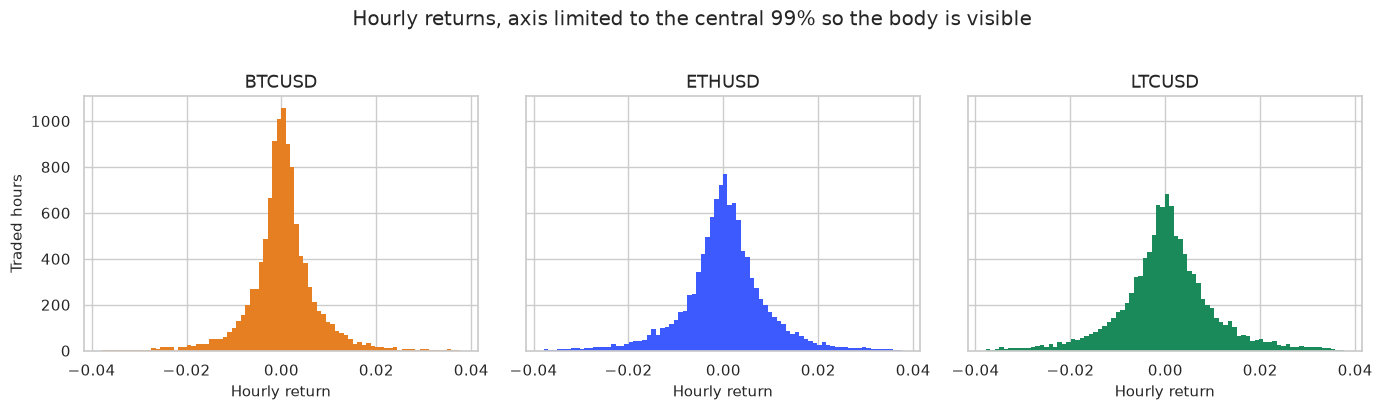

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
central = traded["return"].quantile([0.005, 0.995])
for ax, symbol in zip(axes, ASSET_ORDER):
    series = traded.loc[traded["Symbol"].eq(symbol), "return"].dropna()
    ax.hist(series, bins=80, range=(central.iloc[0], central.iloc[1]), color=ASSET_COLORS[symbol], edgecolor="none")
    ax.set_title(symbol)
    ax.set_xlabel("Hourly return")
axes[0].set_ylabel("Traded hours")
fig.suptitle("Hourly returns, axis limited to the central 99% so the body is visible", y=1.02)
fig.tight_layout()
plt.show()

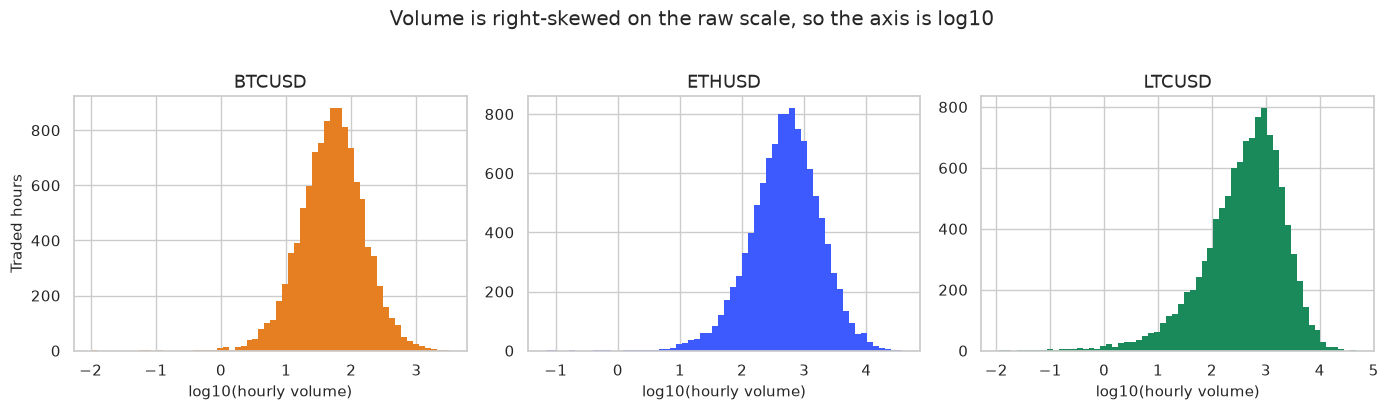

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, symbol in zip(axes, ASSET_ORDER):
    volume = traded.loc[traded["Symbol"].eq(symbol) & traded["Volume"].gt(0), "Volume"]
    ax.hist(np.log10(volume), bins=60, color=ASSET_COLORS[symbol], edgecolor="none")
    ax.set_title(symbol)
    ax.set_xlabel("log10(hourly volume)")
axes[0].set_ylabel("Traded hours")
fig.suptitle("Volume is right-skewed on the raw scale, so the axis is log10", y=1.02)
fig.tight_layout()
plt.show()

On hours that traded, the price level is skewed by the 2021 rally. Bitcoin's hourly close averages about $19,806, the median is $10,935, the minimum is $4,160, and the maximum is $64,626. The skew of the close is 1.36 for Bitcoin, 1.36 for Ether, and 1.41 for Litecoin. Ether's mean close is about $626 and Litecoin's is about $87, which is why the three prices are not put into one model.

Hourly returns sit on zero. Bitcoin's mean return is 0.021% per hour, with a standard deviation of 0.89% and a skew close to zero (0.08). Ether and Litecoin are a little wider, with standard deviations of 1.08% and 1.22%, and both are mildly left-skewed. The histograms are limited to the central 99% so the body is visible. The tails sit well outside that window: Bitcoin's worst hour is -17.1% and its best is +20.1%.

Volume is more skewed than price. Bitcoin's volume skew is 7.1, so the volume figure uses a log10 axis. A typical hour and a busy hour are not on the same scale.


## B. Analytical questions

### 1. Did the three markets trend from January 2020 to April 2021, and where do the March 2020 drop and the later rally show up?

Daily closes, built from the hourly bars, are rebased to 100 at each market's first daily close so Bitcoin's dollar level does not hide Ether and Litecoin. March 2020 is shaded. The table under the chart records the first close, the last close, the full-sample change, and the date of the lowest and highest daily close.

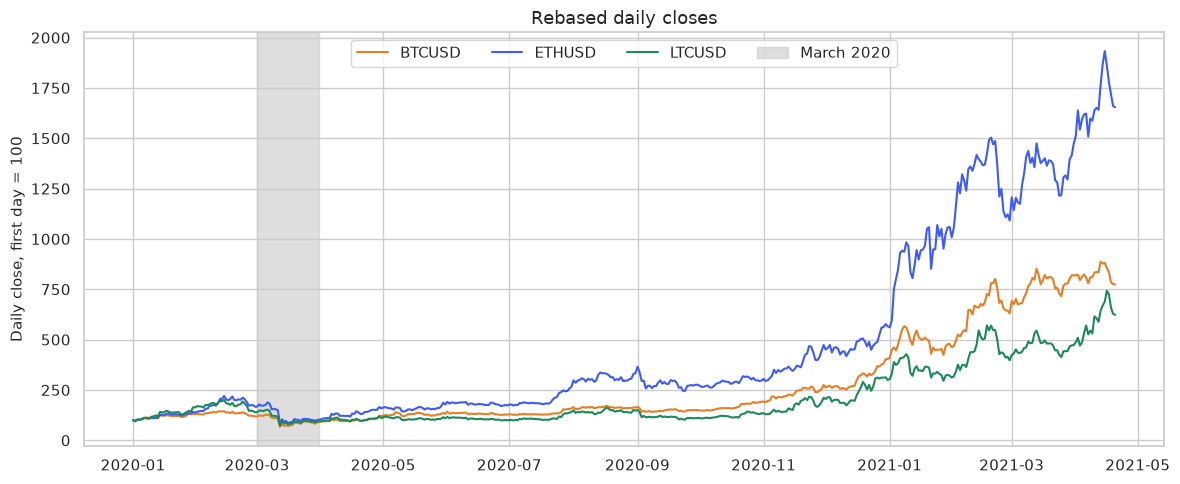

,first_close,last_close,total_change,lowest_close,lowest_on,highest_close,highest_on
Symbol,,,,,,,
BTCUSD,7175.20,55541.69,6.740786,4830.45,2020-03-12,63619.79,2021-04-13
ETHUSD,130.25,2154.38,15.540345,109.28,2020-03-12,2517.52,2021-04-15
LTCUSD,41.57,259.00,5.230455,30.05,2020-03-12,308.76,2021-04-16


In [13]:
close_wide = (
    hourly.pivot_table(index=hourly.index, columns="Symbol", values="Close", aggfunc="last", dropna=False)
    .reindex(columns=ASSET_ORDER)
    .sort_index()
)
daily_close = close_wide.resample("D").last()
rebased = daily_close.div(daily_close.apply(lambda series: series.dropna().iloc[0])).mul(100)

fig, ax = plt.subplots(figsize=(12, 5))
for symbol in ASSET_ORDER:
    ax.plot(
        rebased.index,
        rebased[symbol],
        label=symbol,
        color=ASSET_COLORS[symbol],
        linewidth=1.5,
    )
ax.axvspan(
    pd.Timestamp("2020-03-01"),
    pd.Timestamp("2020-03-31"),
    color="#d0d0d0",
    alpha=0.7,
    label="March 2020",
    zorder=0,
)
ax.set_ylabel("Daily close, first day = 100")
ax.set_title("Rebased daily closes")
ax.legend(ncol=4)
fig.tight_layout()
plt.show()

trend_stats = pd.DataFrame(
    {
        "first_close": daily_close.apply(lambda series: series.dropna().iloc[0]),
        "last_close": daily_close.apply(lambda series: series.dropna().iloc[-1]),
        "total_change": daily_close.apply(
            lambda series: series.dropna().iloc[-1] / series.dropna().iloc[0] - 1
        ),
        "lowest_close": daily_close.min(),
        "lowest_on": daily_close.idxmin(),
        "highest_close": daily_close.max(),
        "highest_on": daily_close.idxmax(),
    }
)
trend_stats

All three markets end far above where they start, and they share the two turning points. Bitcoin's first daily close is $7,175 and its last in the sample is $55,542, a rise of 674%. Ether rises 1,554%, from $130.25 to $2,154. Litecoin rises 523%, from $41.57 to $259.

The lowest daily close of every symbol is on 12 March 2020, inside the shaded month. The highest daily closes are all in mid-April 2021: Bitcoin on 13 April at $63,620, Ether on 15 April at $2,518, and Litecoin on 16 April at $309. March 2020 is a common crash. The rally that follows is also common, and Ether's rebased line pulls away from the other two after November 2020.


### 2. Do hourly Ether and Litecoin returns move with Bitcoin, and does that relationship tighten when Bitcoin volatility is high?

The heatmap is the correlation of hourly returns over the whole sample, using every hour where the two series in a pair both have a return. The line chart is a 168-hour rolling correlation. The table then splits hours by whether Bitcoin's trailing 24-hour volatility is above or below its own median.

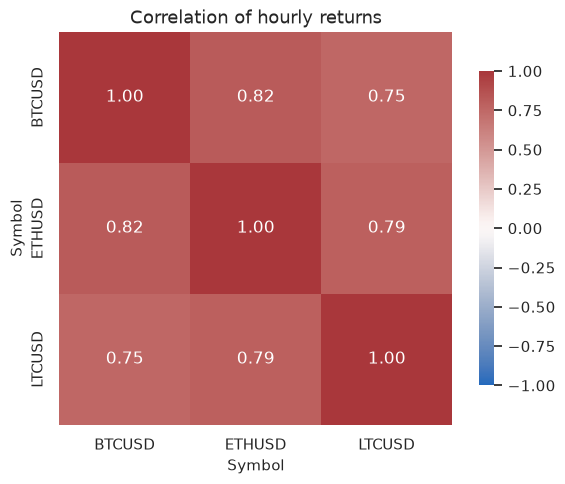

Symbol,BTCUSD,ETHUSD,LTCUSD
Symbol,,,
BTCUSD,1.000000,0.820190,0.753461
ETHUSD,0.820190,1.000000,0.791054
LTCUSD,0.753461,0.791054,1.000000


In [14]:
returns_wide = (
    hourly.pivot_table(index=hourly.index, columns="Symbol", values="return", aggfunc="last", dropna=False)
    .reindex(columns=ASSET_ORDER)
    .sort_index()
)
return_corr = returns_wide.corr()

fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(
    return_corr.loc[ASSET_ORDER, ASSET_ORDER],
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
    cbar_kws={"shrink": 0.8},
)
ax.set_title("Correlation of hourly returns")
fig.tight_layout()
plt.show()
return_corr

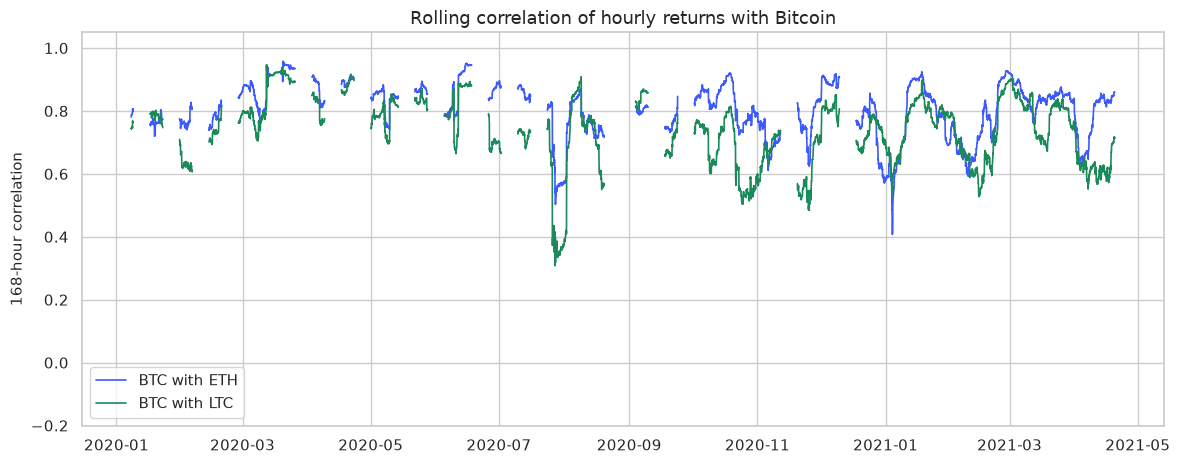

,pair,regime,hourly_return_correlation
0,BTC-ETH,low 24h BTC volatility,0.772349
1,BTC-ETH,high 24h BTC volatility,0.837145
2,BTC-LTC,low 24h BTC volatility,0.666163
3,BTC-LTC,high 24h BTC volatility,0.782918


In [15]:
btc_vol_24 = returns_wide["BTCUSD"].rolling(24).std()
valid_vol = btc_vol_24.notna()
high_vol = valid_vol & btc_vol_24.ge(btc_vol_24.median())
low_vol = valid_vol & btc_vol_24.lt(btc_vol_24.median())

rolling_corr = pd.DataFrame(
    {
        "ETHUSD": returns_wide["BTCUSD"].rolling(168).corr(returns_wide["ETHUSD"]),
        "LTCUSD": returns_wide["BTCUSD"].rolling(168).corr(returns_wide["LTCUSD"]),
    }
)

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(
    rolling_corr.index,
    rolling_corr["ETHUSD"],
    color=ASSET_COLORS["ETHUSD"],
    label="BTC with ETH",
    linewidth=1.2,
)
ax.plot(
    rolling_corr.index,
    rolling_corr["LTCUSD"],
    color=ASSET_COLORS["LTCUSD"],
    label="BTC with LTC",
    linewidth=1.2,
)
ax.set_ylim(-0.2, 1.05)
ax.set_ylabel("168-hour correlation")
ax.set_title("Rolling correlation of hourly returns with Bitcoin")
ax.legend()
fig.tight_layout()
plt.show()


def pair_corr(frame: pd.DataFrame, left: str, right: str) -> float:
    pair = frame[[left, right]].dropna()
    return float(pair[left].corr(pair[right]))


vol_regime = pd.DataFrame(
    [
        {
            "pair": "BTC-ETH",
            "regime": "low 24h BTC volatility",
            "hourly_return_correlation": pair_corr(returns_wide.loc[low_vol], "BTCUSD", "ETHUSD"),
        },
        {
            "pair": "BTC-ETH",
            "regime": "high 24h BTC volatility",
            "hourly_return_correlation": pair_corr(returns_wide.loc[high_vol], "BTCUSD", "ETHUSD"),
        },
        {
            "pair": "BTC-LTC",
            "regime": "low 24h BTC volatility",
            "hourly_return_correlation": pair_corr(returns_wide.loc[low_vol], "BTCUSD", "LTCUSD"),
        },
        {
            "pair": "BTC-LTC",
            "regime": "high 24h BTC volatility",
            "hourly_return_correlation": pair_corr(returns_wide.loc[high_vol], "BTCUSD", "LTCUSD"),
        },
    ]
)
vol_regime

Hourly returns move together. Over the whole sample the Bitcoin-Ether correlation is 0.82, the Bitcoin-Litecoin correlation is 0.75, and the Ether-Litecoin correlation is 0.79.

The 168-hour correlation stays positive. It usually sits between about 0.6 and 0.9, with a few dips, including Litecoin toward 0.3 in late summer 2020 and a sharp dip near the start of 2021.

The link is tighter when Bitcoin is volatile. In hours below the median of Bitcoin's trailing 24-hour volatility, the Bitcoin-Ether correlation is 0.77 and the Bitcoin-Litecoin correlation is 0.67. In the more volatile half those correlations are 0.84 and 0.78. The coins share the hourly move, and they share it more closely when Bitcoin is moving faster.


### 3. Are Bitcoin returns at lags of 1, 6, and 24 hours related to the next-hour return?

This is a lag question. For each lag k from 1 to 24, the bar is the correlation between the return k hours ago and the next hour's Bitcoin return. Lags 1, 6, and 24 are highlighted. The scatter looks at lag 1 only, with the axes limited to +/- 5% so a few extreme hours do not set the scale.

Lags requested in the question:
1    -0.0590
6    -0.0050
24   -0.0393


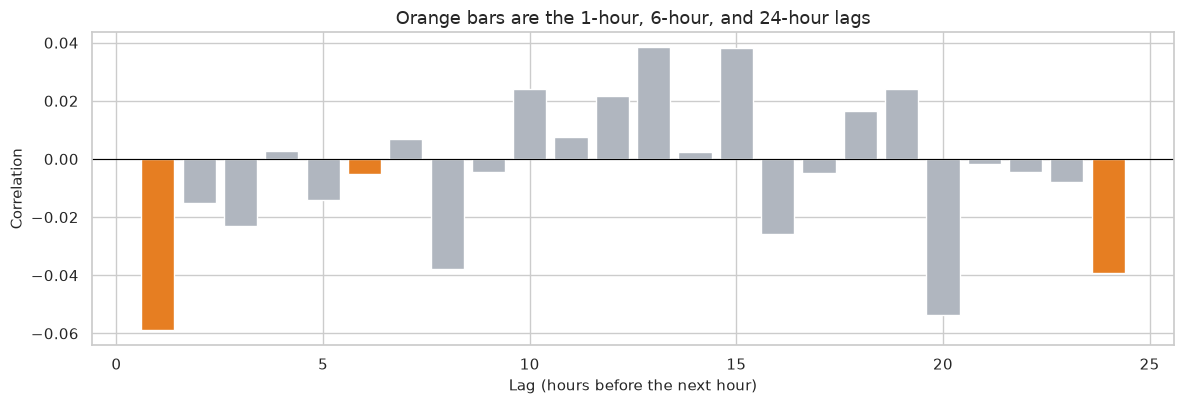

In [16]:
btc_return = returns_wide["BTCUSD"]
next_btc_return = btc_return.shift(-1)
lag_corr = pd.Series(
    {
        lag: next_btc_return.corr(btc_return.shift(lag - 1))
        for lag in range(1, 25)
    },
    name="correlation_with_next_hour_return",
)
print("Lags requested in the question:")
print(lag_corr.loc[[1, 6, 24]].round(4).to_string())

fig, ax = plt.subplots(figsize=(12, 4.2))
bar_colors = ["#e67e22" if lag in (1, 6, 24) else "#b0b6bf" for lag in lag_corr.index]
ax.bar(lag_corr.index, lag_corr.values, color=bar_colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Lag (hours before the next hour)")
ax.set_ylabel("Correlation")
ax.set_title("Orange bars are the 1-hour, 6-hour, and 24-hour lags")
fig.tight_layout()
plt.show()

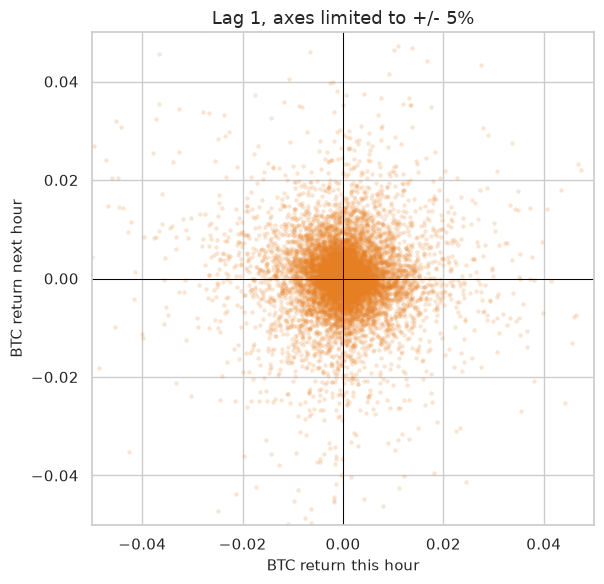

Hours in the scatter, before the axis limit: 10,949


In [17]:
lag_scatter = pd.DataFrame(
    {"return_this_hour": btc_return, "return_next_hour": next_btc_return}
).dropna()

fig, ax = plt.subplots(figsize=(6.2, 6))
ax.scatter(
    lag_scatter["return_this_hour"],
    lag_scatter["return_next_hour"],
    s=10,
    alpha=0.2,
    color=ASSET_COLORS["BTCUSD"],
    linewidths=0,
)
ax.axhline(0, color="black", linewidth=0.7)
ax.axvline(0, color="black", linewidth=0.7)
ax.set_xlim(-0.05, 0.05)
ax.set_ylim(-0.05, 0.05)
ax.set_xlabel("BTC return this hour")
ax.set_ylabel("BTC return next hour")
ax.set_title("Lag 1, axes limited to +/- 5%")
fig.tight_layout()
plt.show()
print(f"Hours in the scatter, before the axis limit: {len(lag_scatter):,}")

The lag correlations are small. The Bitcoin return one hour earlier correlates with the next-hour return at -0.059. The 6-hour lag is -0.005. The 24-hour lag is -0.039. Across lags 1 through 24, nothing is larger than about 0.06 in absolute value.

The scatter is a cloud around the origin, on 10,949 hours, rather than a line. The negative sign at one hour and at 24 hours is a faint mean-reversion trace. It is too weak to carry a next-hour forecast by itself. An hourly Bitcoin return is close to uncorrelated with its own recent past.


### 4. How do the 24-hour and 168-hour averages track the Bitcoin close, and does the gap from the 24-hour average predict the next-hour return?

This is the moving-average question. The line chart zooms in on the ten days on either side of Bitcoin's lowest hourly close, which is where a slow average and a fast average separate the most. The bars then split every hour into deciles of `(close - 24-hour average) / 24-hour average`. Decile 1 is the hours furthest below the average. The bar height is the mean return in the following hour.

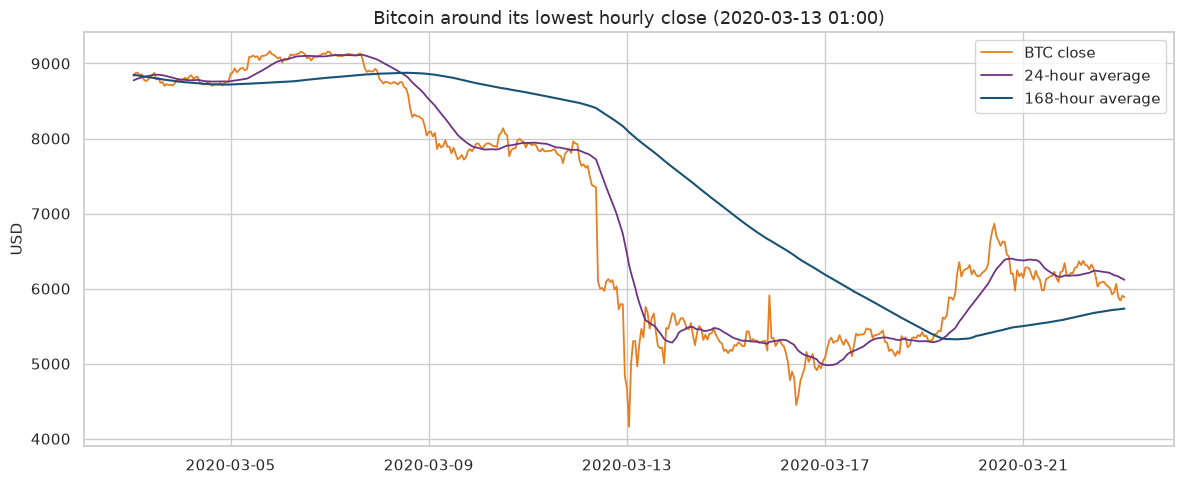

In [18]:
btc_close = close_wide["BTCUSD"].sort_index()
ma_24 = btc_close.rolling(24, min_periods=24).mean()
ma_168 = btc_close.rolling(168, min_periods=168).mean()
lowest_at = btc_close.idxmin()
zoom = btc_close.loc[lowest_at - pd.Timedelta(days=10) : lowest_at + pd.Timedelta(days=10)]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(zoom.index, zoom, color=ASSET_COLORS["BTCUSD"], linewidth=1.3, label="BTC close")
ax.plot(ma_24.loc[zoom.index], color="#6c3483", linewidth=1.3, label="24-hour average")
ax.plot(ma_168.loc[zoom.index], color="#1a5276", linewidth=1.5, label="168-hour average")
ax.set_ylabel("USD")
ax.set_title(f"Bitcoin around its lowest hourly close ({lowest_at:%Y-%m-%d %H:%M})")
ax.legend()
fig.tight_layout()
plt.show()

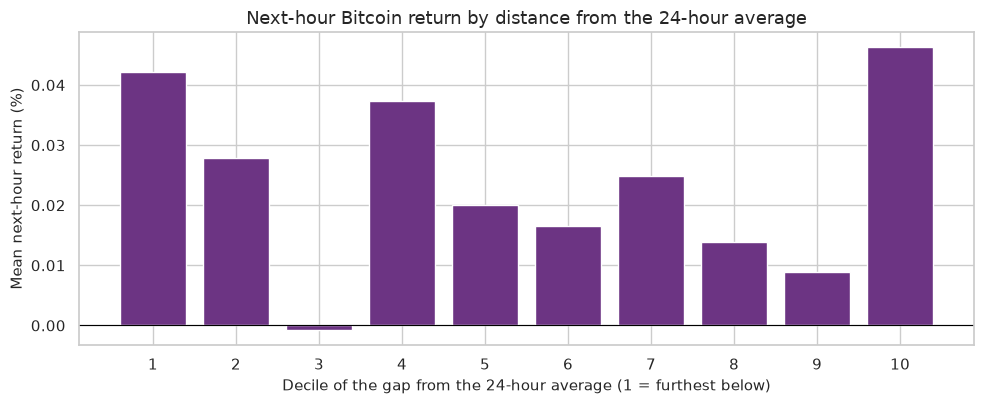

,hours,mean_gap,mean_next_return
decile,,,
1,1054,-0.038923,0.000421
2,1053,-0.013621,0.000278
3,1053,-0.006234,-0.000008
4,1053,-0.002223,0.000374
5,1053,0.000714,0.000201
6,1053,0.003492,0.000165
7,1053,0.006818,0.000248
8,1053,0.011466,0.000138
9,1053,0.019284,0.000089


In [19]:
ma_gap = (btc_close - ma_24) / ma_24
gap_frame = pd.DataFrame(
    {"ma_gap": ma_gap, "next_return": btc_close.pct_change().shift(-1)}
).dropna()
gap_frame["decile"] = pd.qcut(gap_frame["ma_gap"], 10, labels=False, duplicates="drop") + 1
gap_deciles = gap_frame.groupby("decile").agg(
    hours=("next_return", "size"),
    mean_gap=("ma_gap", "mean"),
    mean_next_return=("next_return", "mean"),
)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(gap_deciles.index.astype(str), gap_deciles["mean_next_return"] * 100, color="#6c3483")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Decile of the gap from the 24-hour average (1 = furthest below)")
ax.set_ylabel("Mean next-hour return (%)")
ax.set_title("Next-hour Bitcoin return by distance from the 24-hour average")
fig.tight_layout()
plt.show()
gap_deciles

The lowest hourly Bitcoin close is at 01:00 on 13 March 2020. In the ten days on either side of that hour, the 24-hour average follows the price down within about a day. The 168-hour average is still near $8,500 when the price has already spiked through $5,000, and it takes several more days to arrive. The averages describe the path. They lag it.

The deciles ask whether the size of that gap predicts the next hour. It does not line up in either direction. Hours furthest below the 24-hour average (decile 1, mean gap -3.9%) have a mean next-hour return of 0.042%. Hours furthest above it (decile 10, mean gap +4.3%) have a mean next-hour return of 0.046%. The deciles in between bounce around zero, and decile 3 is slightly negative. Those gaps between deciles are small beside the 0.89% standard deviation of an hourly Bitcoin return. Distance from the 24-hour average is not a next-hour signal.


### 5. Is there an hour-of-day or day-of-week pattern in volume and absolute returns, even though the market never closes?

Only hours that actually traded are included. Volume is divided by each symbol's own average so Bitcoin's coin volume does not dominate the scale. Absolute return is already a percent-style move and can share an axis. The timestamps are used as stored in the files; Gemini publishes these bars in UTC.

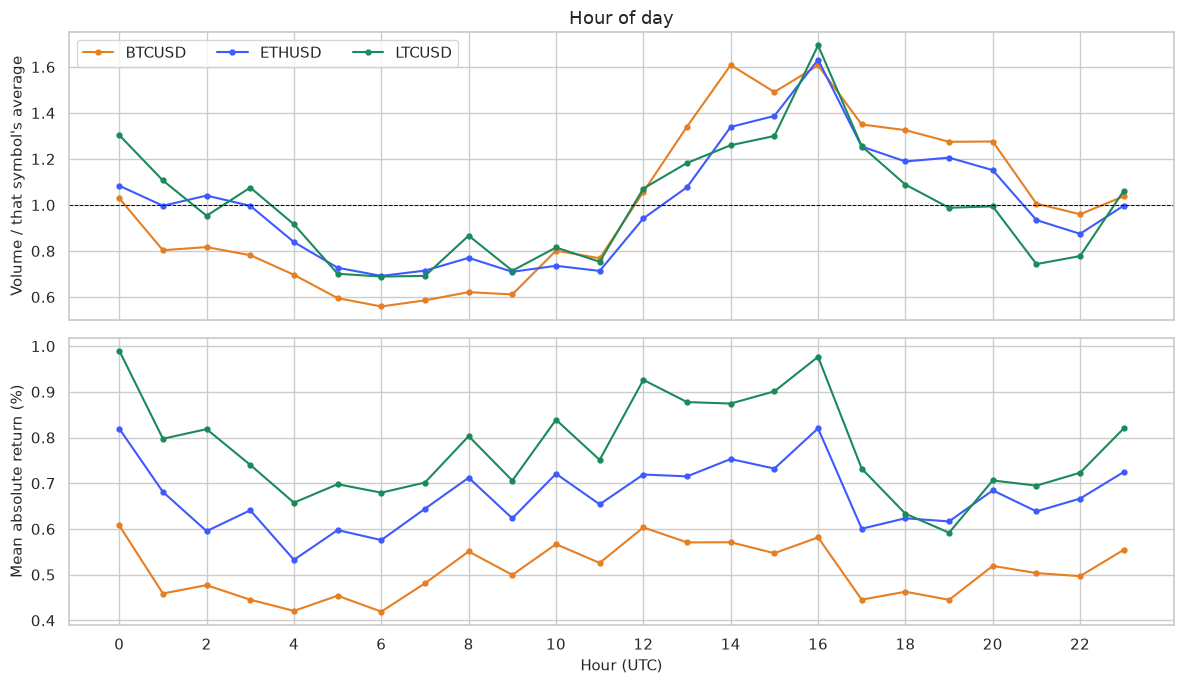

Hour with the highest average volume:
Symbol
BTCUSD    14
ETHUSD    16
LTCUSD    16
             volume_vs_own_average  mean_abs_return_pct
Symbol hour                                            
BTCUSD 0                     1.029                0.608
       1                     0.803                0.459
       2                     0.817                0.477
       3                     0.782                0.445
       4                     0.696                0.421
       5                     0.595                0.454
       6                     0.559                0.419
       7                     0.585                0.481
       8                     0.621                0.551
       9                     0.611                0.500
       10                    0.801                0.567
       11                    0.768                0.526
       12                    1.056                0.603
       13                    1.341                0.571
       14           

volume_vs_own_average  mean_abs_return_pct
Symbol hour                                            
BTCUSD 0                     1.029                0.608
       1                     0.803                0.459
       2                     0.817                0.477
       3                     0.782                0.445
       4                     0.696                0.421
...                            ...                  ...
LTCUSD 19                    0.988                0.592
       20                    0.994                0.706
       21                    0.743                0.695
       22                    0.778                0.723
       23                    1.062                0.820

[72 rows x 2 columns]

In [20]:
calendar = traded.copy()
calendar["hour"] = calendar.index.hour
calendar["dow"] = calendar.index.day_of_week
calendar["abs_return"] = calendar["return"].abs()

hour_profile = calendar.groupby(["Symbol", "hour"]).agg(
    mean_volume=("Volume", "mean"),
    mean_abs_return=("abs_return", "mean"),
)
hour_profile["volume_vs_own_average"] = hour_profile["mean_volume"] / hour_profile.groupby("Symbol")[
    "mean_volume"
].transform("mean")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for symbol in ASSET_ORDER:
    profile = hour_profile.loc[symbol]
    axes[0].plot(
        profile.index,
        profile["volume_vs_own_average"],
        color=ASSET_COLORS[symbol],
        marker="o",
        markersize=3.5,
        label=symbol,
    )
    axes[1].plot(
        profile.index,
        profile["mean_abs_return"] * 100,
        color=ASSET_COLORS[symbol],
        marker="o",
        markersize=3.5,
        label=symbol,
    )
axes[0].axhline(1, color="black", linewidth=0.7, linestyle="--")
axes[0].set_ylabel("Volume / that symbol's average")
axes[0].set_title("Hour of day")
axes[0].legend(ncol=3)
axes[1].set_ylabel("Mean absolute return (%)")
axes[1].set_xlabel("Hour (UTC)")
axes[1].set_xticks(range(0, 24, 2))
fig.tight_layout()
plt.show()

peak_hours = hour_profile["mean_volume"].groupby("Symbol").idxmax().apply(lambda key: int(key[1]))
print("Hour with the highest average volume:")
print(peak_hours.reindex(ASSET_ORDER).to_string())
hour_table = hour_profile[["volume_vs_own_average", "mean_abs_return"]].copy()
hour_table["volume_vs_own_average"] = hour_table["volume_vs_own_average"].round(3)
hour_table["mean_abs_return_pct"] = (hour_table["mean_abs_return"] * 100).round(3)
hour_table = hour_table.drop(columns="mean_abs_return")
print(hour_table.to_string())
hour_table


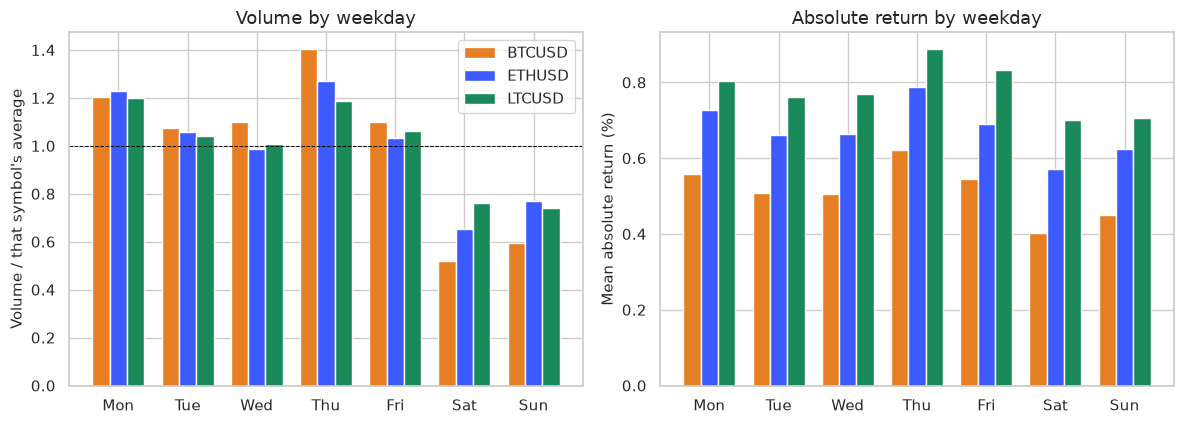

            volume_vs_own_average  mean_abs_return_pct
Symbol dow                                            
BTCUSD Mon                  1.205                0.557
       Tue                  1.076                0.508
       Wed                  1.097                0.504
       Thu                  1.403                0.623
       Fri                  1.101                0.545
       Sat                  0.522                0.402
       Sun                  0.595                0.450
ETHUSD Mon                  1.229                0.726
       Tue                  1.058                0.661
       Wed                  0.988                0.663
       Thu                  1.269                0.788
       Fri                  1.032                0.690
       Sat                  0.655                0.572
       Sun                  0.769                0.623
LTCUSD Mon                  1.201                0.804
       Tue                  1.039                0.762
       Wed

volume_vs_own_average  mean_abs_return_pct
Symbol dow                                            
BTCUSD Mon                  1.205                0.557
       Tue                  1.076                0.508
       Wed                  1.097                0.504
       Thu                  1.403                0.623
       Fri                  1.101                0.545
       Sat                  0.522                0.402
       Sun                  0.595                0.450
ETHUSD Mon                  1.229                0.726
       Tue                  1.058                0.661
       Wed                  0.988                0.663
       Thu                  1.269                0.788
       Fri                  1.032                0.690
       Sat                  0.655                0.572
       Sun                  0.769                0.623
LTCUSD Mon                  1.201                0.804
       Tue                  1.039                0.762
       Wed                  1.010                0.770
       Thu                  1.186                0.888
       Fri                  1.062                0.833
       Sat                  0.761                0.702
       Sun                  0.741                0.706

In [21]:
dow_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow_profile = calendar.groupby(["Symbol", "dow"]).agg(
    mean_volume=("Volume", "mean"),
    mean_abs_return=("abs_return", "mean"),
)
dow_profile["volume_vs_own_average"] = dow_profile["mean_volume"] / dow_profile.groupby("Symbol")[
    "mean_volume"
].transform("mean")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
x = np.arange(7)
width = 0.25
for offset, symbol in enumerate(ASSET_ORDER):
    profile = dow_profile.loc[symbol].reindex(range(7))
    axes[0].bar(
        x + (offset - 1) * width,
        profile["volume_vs_own_average"],
        width=width,
        color=ASSET_COLORS[symbol],
        label=symbol,
    )
    axes[1].bar(
        x + (offset - 1) * width,
        profile["mean_abs_return"] * 100,
        width=width,
        color=ASSET_COLORS[symbol],
        label=symbol,
    )
for ax, ylabel, title in (
    (axes[0], "Volume / that symbol's average", "Volume by weekday"),
    (axes[1], "Mean absolute return (%)", "Absolute return by weekday"),
):
    ax.set_xticks(x, dow_labels)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[0].axhline(1, color="black", linewidth=0.7, linestyle="--")
axes[0].legend()
fig.tight_layout()
plt.show()

dow_shown = dow_profile[["volume_vs_own_average", "mean_abs_return"]].copy()
dow_shown["volume_vs_own_average"] = dow_shown["volume_vs_own_average"].round(3)
dow_shown["mean_abs_return_pct"] = (dow_shown["mean_abs_return"] * 100).round(3)
dow_shown = dow_shown.drop(columns="mean_abs_return")
dow_shown = dow_shown.rename(index=dict(enumerate(dow_labels)), level="dow")
print(dow_shown.to_string())
dow_shown


A market that never closes still has an hour-of-day and a weekday pattern. Hour 06:00 UTC is the quietest volume hour for all three symbols: 0.559 of Bitcoin's own average, 0.692 of Ether's, and 0.689 of Litecoin's. Bitcoin's busiest hour is 14:00 UTC, at 1.608 times its average. Hour 16:00 is almost the same for Bitcoin, at 1.607. Ether peaks at 16:00 UTC at 1.631 times its average, and Litecoin at 16:00 UTC at 1.694.

Absolute returns follow that shape. Bitcoin's mean absolute return is 0.419% at 06:00, 0.608% at 00:00, and 0.582% at 16:00. Ether is 0.576% at 06:00 and 0.820% at both 00:00 and 16:00. Litecoin is 0.679% at 06:00, 0.990% at 00:00, and 0.977% at 16:00. Litecoin's mean absolute return is larger than Bitcoin's in every hour.

Thursday has the highest mean absolute return for all three: 0.623% for Bitcoin, 0.788% for Ether, and 0.888% for Litecoin. It is also the highest-volume day for Bitcoin, at 1.403 times its average, and for Ether, at 1.269. Litecoin's highest-volume day is Monday, at 1.201, with Thursday second at 1.186. Saturday is the lowest-volume day for Bitcoin (0.522) and Ether (0.655), and it has the smallest absolute return for all three: 0.402%, 0.572%, and 0.702%. Litecoin's lowest-volume day is Sunday, at 0.741, just under Saturday's 0.761.


### 6. Does unusually high volume over the previous 24 hours line up with a larger move in the next hour?

For Bitcoin, each traded hour is scored by the mean volume over the 24 hours ending at that hour. The average is known when the hour closes. Hours are split into deciles of that average. Decile 1 is the quietest trailing day. The bar height is the mean absolute Bitcoin return in the following hour.

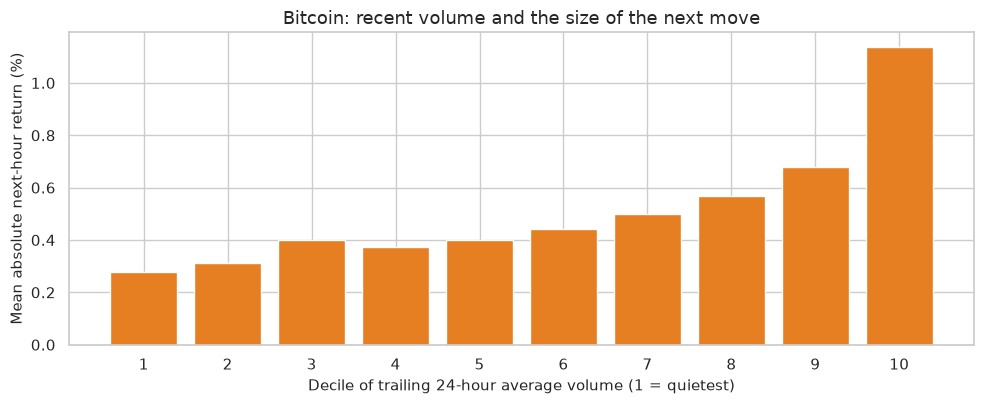

,hours,mean_volume_24h,mean_next_abs_return
decile,,,
1,1095,19.214104,0.002783
2,1094,32.991731,0.003126
3,1095,45.506391,0.003997
4,1094,56.880874,0.003744
5,1095,66.845298,0.004016
6,1094,77.376174,0.004421
7,1094,89.643000,0.004981
8,1095,107.120659,0.005684
9,1094,140.839961,0.006805


In [22]:
btc_hourly = hourly.loc[hourly["Symbol"].eq("BTCUSD")].sort_index()
volume_frame = pd.DataFrame(
    {
        "volume_24h": btc_hourly["Volume"].rolling(24, min_periods=24).mean(),
        "next_abs_return": btc_hourly["return"].shift(-1).abs(),
        "traded": btc_hourly["minutes"].gt(0),
    }
).dropna()
volume_frame = volume_frame.loc[volume_frame["traded"]].copy()
volume_frame["decile"] = pd.qcut(volume_frame["volume_24h"], 10, labels=False, duplicates="drop") + 1
volume_deciles = volume_frame.groupby("decile").agg(
    hours=("next_abs_return", "size"),
    mean_volume_24h=("volume_24h", "mean"),
    mean_next_abs_return=("next_abs_return", "mean"),
)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(
    volume_deciles.index.astype(str),
    volume_deciles["mean_next_abs_return"] * 100,
    color=ASSET_COLORS["BTCUSD"],
)
ax.set_xlabel("Decile of trailing 24-hour average volume (1 = quietest)")
ax.set_ylabel("Mean absolute next-hour return (%)")
ax.set_title("Bitcoin: recent volume and the size of the next move")
fig.tight_layout()
plt.show()
volume_deciles

Yes. The size of the next Bitcoin move rises with the trailing 24-hour volume, and the rise is ordered. In the quietest decile the mean volume is about 19 coins per hour and the mean absolute next-hour return is 0.28%. In the loudest decile the mean volume is about 277 and the mean absolute next-hour return is 1.14%, about four times as large. The steps in between mostly climb as well. Recent activity says something about how large the next hour will be. It does not, on this chart, say which way the hour will go.


## C. Forecasting the next Bitcoin hour

The target is the next hour's BTC close. Two feature matrices share one chronological split.

The first matrix uses only information other than the raw close: Bitcoin return lags, the 24-hour and 168-hour averages, the gap from the 24-hour average, trailing volume, hour-of-day and day-of-week cycles, and the current hourly return of Ether and Litecoin. Persistence, which predicts that the next close equals the current close, is the baseline for this matrix. An unpenalized linear regression is the alpha-equals-zero end of the ridge search. Ridge and histogram gradient boosting are tuned on the training period.

The second matrix is the first one plus the current Bitcoin close. That close is known when the next hour is forecast. Ridge and gradient boosting are tuned again on it, with a scaler fit on the training rows of this wider matrix only. This asks whether the other features improve a forecast that is allowed to start from the last price.

The split is 70% train, 15% validation, and 15% test. Every scaler and every hyperparameter search sees the training period only, through `TimeSeriesSplit` scored by mean absolute error. Validation chooses the experiment. The test period is scored once, after that choice.

The close itself is usually a wandering level. The return is the change in that level. The next cell reports Augmented Dickey-Fuller tests for both, so a high R-squared on the price level is not mistaken for evidence that a model beat the last observed price.


In [23]:
def adf_row(series: pd.Series, name: str) -> dict:
    clean = series.dropna()
    statistic, p_value, used_lag, nobs, critical, _ = adfuller(clean, autolag="AIC", result_object=False)
    return {
        "series": name,
        "adf_statistic": statistic,
        "p_value": p_value,
        "lags_used": used_lag,
        "observations": nobs,
        "critical_5pct": critical["5%"],
    }


stationarity = pd.DataFrame(
    [
        adf_row(close_wide["BTCUSD"], "BTC hourly close"),
        adf_row(returns_wide["BTCUSD"], "BTC hourly return"),
        adf_row(returns_wide["ETHUSD"], "ETH hourly return"),
        adf_row(returns_wide["LTCUSD"], "LTC hourly return"),
    ]
).set_index("series")
stationarity

,adf_statistic,p_value,lags_used,observations,critical_5pct
series,,,,,
BTC hourly close,0.707138,9.899793e-01,39,10947,-2.861804
BTC hourly return,-19.198509,0.000000e+00,31,10936,-2.861804
ETH hourly return,-16.643352,1.627433e-29,37,10930,-2.861804
LTC hourly return,-16.828293,1.163455e-29,37,10930,-2.861804


The Augmented Dickey-Fuller test does not reject a unit root in the Bitcoin hourly close. The statistic is 0.71, the p-value is 0.99, and the 5% critical value is -2.86. The same test rejects a unit root in hourly returns for all three coins. Bitcoin's return statistic is -19.2, with a p-value that prints as zero at this precision. Ether and Litecoin returns are rejected at the same strength.

The close is a wandering level. The return is a stationary change in that level. Missing hours are removed inside the test, so the result describes the observed sequence. A forecast of the price level can look accurate, with an R-squared near 1, whenever it stays close to the last print. The model comparison below uses mean absolute error against a persistence forecast, which is the last close carried forward one hour.


In [24]:
btc_volume = hourly.loc[hourly["Symbol"].eq("BTCUSD"), "Volume"].copy()
if btc_volume.index.has_duplicates:
    raise ValueError("BTC hourly index has duplicate timestamps.")

model_source = (
    close_wide[["BTCUSD"]]
    .rename(columns={"BTCUSD": "close"})
    .join(btc_volume.rename("volume"), how="left")
    .join(
        returns_wide.rename(
            columns={"BTCUSD": "btc_ret", "ETHUSD": "eth_ret", "LTCUSD": "ltc_ret"}
        ),
        how="left",
    )
    .sort_index()
)

model_source["ret_lag1"] = model_source["btc_ret"]
model_source["ret_lag6"] = model_source["btc_ret"].shift(5)
model_source["ret_lag24"] = model_source["btc_ret"].shift(23)
model_source["ma_24"] = model_source["close"].rolling(24, min_periods=24).mean()
model_source["ma_168"] = model_source["close"].rolling(168, min_periods=168).mean()
model_source["ma_gap_24"] = (model_source["close"] - model_source["ma_24"]) / model_source["ma_24"]
model_source["volume_24h"] = model_source["volume"].rolling(24, min_periods=24).mean()
hour_of_day = model_source.index.hour
day_of_week = model_source.index.day_of_week
model_source["hour_sin"] = np.sin(2 * np.pi * hour_of_day / 24)
model_source["hour_cos"] = np.cos(2 * np.pi * hour_of_day / 24)
model_source["dow_sin"] = np.sin(2 * np.pi * day_of_week / 7)
model_source["dow_cos"] = np.cos(2 * np.pi * day_of_week / 7)
model_source["eth_ret_lag1"] = model_source["eth_ret"]
model_source["ltc_ret_lag1"] = model_source["ltc_ret"]
model_source["next_close"] = model_source["close"].shift(-1)

feature_columns = [
    "ret_lag1",
    "ret_lag6",
    "ret_lag24",
    "ma_24",
    "ma_168",
    "ma_gap_24",
    "volume_24h",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "eth_ret_lag1",
    "ltc_ret_lag1",
]
model_frame = model_source[feature_columns + ["close", "next_close"]].dropna().sort_index()
print(f"Rows before dropping the warm-up window and incomplete hours: {len(model_source):,}")
print(f"Rows available for the forecast: {len(model_frame):,}")
print(f"Feature window: {model_frame.index.min()} to {model_frame.index.max()}")
model_frame[feature_columns].head()

Rows before dropping the warm-up window and incomplete hours: 11,401
Rows available for the forecast: 7,818
Feature window: 2020-01-07 23:00:00 to 2021-04-19 23:00:00


,ret_lag1,ret_lag6,ret_lag24,ma_24,ma_168,ma_gap_24,volume_24h,hour_sin,hour_cos,dow_sin,dow_cos,eth_ret_lag1,ltc_ret_lag1
timestamp,,,,,,,,,,,,,
2020-01-07 23:00:00,0.013589,0.012556,0.016010,7928.132917,7387.440714,0.029057,77.941132,-0.258819,0.965926,0.781831,0.623490,0.006611,0.002596
2020-01-08 00:00:00,0.035150,0.004778,0.002386,7951.394167,7395.156429,0.062112,70.219837,0.000000,1.000000,0.974928,-0.222521,0.032139,0.046386
2020-01-08 01:00:00,-0.008098,0.011893,-0.000426,7971.021667,7402.245179,0.050917,71.575414,0.258819,0.965926,0.974928,-0.222521,-0.013200,-0.015464
2020-01-08 02:00:00,-0.011027,-0.018838,-0.000395,7986.940833,7408.581250,0.037257,73.372421,0.500000,0.866025,0.974928,-0.222521,-0.007614,-0.003979
2020-01-08 03:00:00,0.002063,0.003750,-0.006718,8003.702083,7415.144107,0.037220,75.442431,0.707107,0.707107,0.974928,-0.222521,0.000691,0.002313


Rows that do not yet have a 168-hour average, a 24-hour lag, or a next close are dropped before the split. So are hours where Ether or Litecoin does not have a return, including the hours that follow an outage longer than two hours. What remains is one ordered Bitcoin series.

The split is a cut in time, not a random sample. The first 70% of those rows train the scaler and the models. The next 15% is the validation period used to compare experiments. The last 15% is untouched until a winner has been chosen. `StandardScaler` is fit on the training block and then applied to the later blocks.

In [25]:
n_rows = len(model_frame)
train_end = int(n_rows * 0.70)
val_end = int(n_rows * 0.85)
train = model_frame.iloc[:train_end]
valid = model_frame.iloc[train_end:val_end]
test = model_frame.iloc[val_end:]

close_columns = feature_columns + ["close"]
X_train = train[feature_columns]
X_train_c = train[close_columns]
y_train = train["next_close"]
X_valid = valid[feature_columns]
X_valid_c = valid[close_columns]
y_valid = valid["next_close"]
X_test = test[feature_columns]
X_test_c = test[close_columns]
y_test = test["next_close"]

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_valid_s = scaler.transform(X_valid)
X_test_s = scaler.transform(X_test)

scaler_c = StandardScaler()
X_train_c_s = scaler_c.fit_transform(X_train_c)
X_valid_c_s = scaler_c.transform(X_valid_c)
X_test_c_s = scaler_c.transform(X_test_c)

split_summary = pd.DataFrame(
    {
        "rows": [len(train), len(valid), len(test)],
        "starts": [train.index.min(), valid.index.min(), test.index.min()],
        "ends": [train.index.max(), valid.index.max(), test.index.max()],
    },
    index=["train", "validation", "test"],
)
split_summary


,rows,starts,ends
train,5472,2020-01-07 23:00:00,2021-01-12 05:00:00
validation,1173,2021-01-12 06:00:00,2021-03-02 02:00:00
test,1173,2021-03-02 03:00:00,2021-04-19 23:00:00


After the warm-up of 168 hours, and after hours that touch a long outage or lack an Ether or Litecoin return, 7,818 hours remain from the 11,401-hour clock. The usable window runs from 7 January 2020 23:00 to 19 April 2021 23:00.

The cut is chronological. The training block is the first 5,472 of those hours, through 12 January 2021 05:00. Validation is the next 1,173 hours, through 2 March 2021 02:00. The test block is the last 1,173 hours, from 2 March 2021 03:00 to 19 April 2021 23:00. The scaler is fit on the training block only.


### Experiments

Persistence predicts the next close with the current close. On the matrix without that close, linear regression is unpenalized and ridge is tuned over a grid that extends below the old boundary of 0.01. Histogram gradient boosting is tuned on the same rows. Both fitted models are then tuned again on the matrix that includes the current close. The validation mean absolute error, in dollars of Bitcoin, picks the winner.


In [26]:
def regression_scores(y_true: pd.Series, y_pred) -> dict:
    prediction = np.asarray(y_pred, dtype=float)
    return {
        "MAE": float(mean_absolute_error(y_true, prediction)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, prediction))),
        "R2": float(r2_score(y_true, prediction)),
    }


persistence_train = regression_scores(y_train, train["close"])
persistence_valid = regression_scores(y_valid, valid["close"])
print("Training:", {key: round(value, 3) for key, value in persistence_train.items()})
print("Validation:", {key: round(value, 3) for key, value in persistence_valid.items()})

Training: {'MAE': 71.887, 'RMSE': 155.178, 'R2': 0.999}
Validation: {'MAE': 347.44, 'RMSE': 497.626, 'R2': 0.996}


In [27]:
RIDGE_ALPHAS = [1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0, 100.0, 1_000.0, 10_000.0]
ridge_search = GridSearchCV(
    Ridge(),
    param_grid={"alpha": RIDGE_ALPHAS},
    cv=TimeSeriesSplit(n_splits=4),
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)
ridge_search.fit(X_train_s, y_train)
ridge = ridge_search.best_estimator_
ridge_train = regression_scores(y_train, ridge.predict(X_train_s))
ridge_valid = regression_scores(y_valid, ridge.predict(X_valid_s))
print("Best alpha:", ridge_search.best_params_["alpha"])
print("Grid endpoints:", RIDGE_ALPHAS[0], RIDGE_ALPHAS[-1])
print("Training:", {key: round(value, 3) for key, value in ridge_train.items()})
print("Validation:", {key: round(value, 3) for key, value in ridge_valid.items()})


Best alpha: 0.0001
Grid endpoints: 0.0001 10000.0
Training: {'MAE': 126.405, 'RMSE': 283.336, 'R2': 0.998}
Validation: {'MAE': 729.725, 'RMSE': 1016.762, 'R2': 0.982}


In [28]:
linear = LinearRegression()
linear.fit(X_train_s, y_train)
linear_train = regression_scores(y_train, linear.predict(X_train_s))
linear_valid = regression_scores(y_valid, linear.predict(X_valid_s))
print("Unpenalized linear regression on the features without the current close")
print("Training:", {key: round(value, 3) for key, value in linear_train.items()})
print("Validation:", {key: round(value, 3) for key, value in linear_valid.items()})


Unpenalized linear regression on the features without the current close
Training: {'MAE': 126.405, 'RMSE': 283.336, 'R2': 0.998}
Validation: {'MAE': 729.725, 'RMSE': 1016.762, 'R2': 0.982}


In [29]:
boost_search = GridSearchCV(
    HistGradientBoostingRegressor(random_state=42),
    param_grid={
        "learning_rate": [0.05, 0.1],
        "max_depth": [3, 6],
        "max_iter": [150, 300],
    },
    cv=TimeSeriesSplit(n_splits=4),
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)
boost_search.fit(X_train_s, y_train)
boost = boost_search.best_estimator_
boost_train = regression_scores(y_train, boost.predict(X_train_s))
boost_valid = regression_scores(y_valid, boost.predict(X_valid_s))
print("Best hyperparameters:", boost_search.best_params_)
print("Training:", {key: round(value, 3) for key, value in boost_train.items()})
print("Validation:", {key: round(value, 3) for key, value in boost_valid.items()})

Best hyperparameters: {'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 300}
Training: {'MAE': 82.148, 'RMSE': 144.327, 'R2': 1.0}
Validation: {'MAE': 4995.702, 'RMSE': 6956.809, 'R2': 0.179}


In [30]:
ridge_close_search = GridSearchCV(
    Ridge(),
    param_grid={"alpha": RIDGE_ALPHAS},
    cv=TimeSeriesSplit(n_splits=4),
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)
ridge_close_search.fit(X_train_c_s, y_train)
ridge_close = ridge_close_search.best_estimator_
ridge_close_train = regression_scores(y_train, ridge_close.predict(X_train_c_s))
ridge_close_valid = regression_scores(y_valid, ridge_close.predict(X_valid_c_s))
print("Best alpha, with the current close:", ridge_close_search.best_params_["alpha"])
print("Training:", {key: round(value, 3) for key, value in ridge_close_train.items()})
print("Validation:", {key: round(value, 3) for key, value in ridge_close_valid.items()})


Best alpha, with the current close: 0.01
Training: {'MAE': 71.695, 'RMSE': 154.581, 'R2': 1.0}
Validation: {'MAE': 347.653, 'RMSE': 498.241, 'R2': 0.996}


In [31]:
boost_close_search = GridSearchCV(
    HistGradientBoostingRegressor(random_state=42),
    param_grid={
        "learning_rate": [0.05, 0.1],
        "max_depth": [3, 6],
        "max_iter": [150, 300],
    },
    cv=TimeSeriesSplit(n_splits=4),
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)
boost_close_search.fit(X_train_c_s, y_train)
boost_close = boost_close_search.best_estimator_
boost_close_train = regression_scores(y_train, boost_close.predict(X_train_c_s))
boost_close_valid = regression_scores(y_valid, boost_close.predict(X_valid_c_s))
print("Best hyperparameters, with the current close:", boost_close_search.best_params_)
print("Training:", {key: round(value, 3) for key, value in boost_close_train.items()})
print("Validation:", {key: round(value, 3) for key, value in boost_close_valid.items()})


Best hyperparameters, with the current close: {'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 300}
Training: {'MAE': 77.343, 'RMSE': 132.753, 'R2': 1.0}
Validation: {'MAE': 4350.366, 'RMSE': 6522.394, 'R2': 0.278}


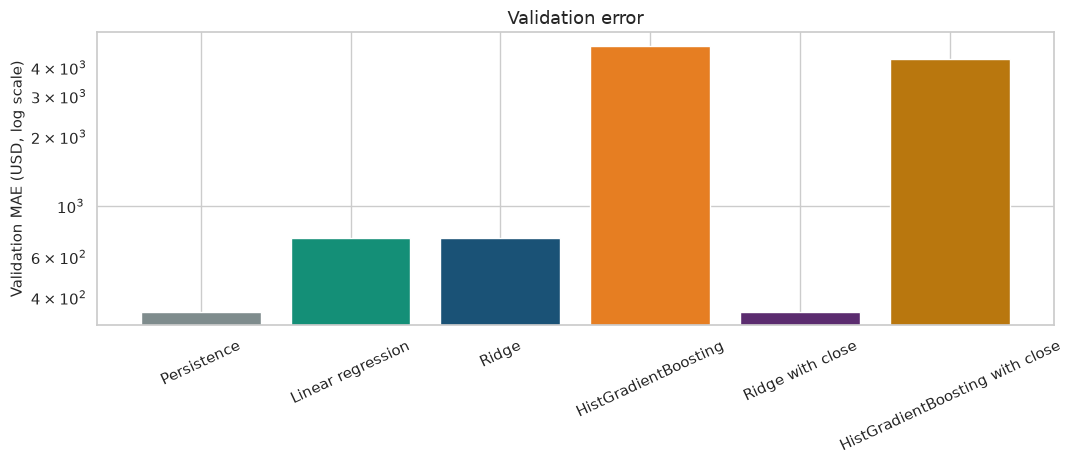

,Hyperparameters,Train MAE,Train RMSE,Train R2,Val MAE,Val RMSE,Val R2,Beats persistence on val MAE
Experiment,,,,,,,,
Persistence,next close = current close,71.887,155.178,0.999,347.440,497.626,0.996,None
Linear regression,"no close, alpha = 0",126.405,283.336,0.998,729.725,1016.762,0.982,False
Ridge,"no close, alpha=0.0001",126.405,283.336,0.998,729.725,1016.762,0.982,False
HistGradientBoosting,"no close, learning_rate=0.1, max_depth=3, max_...",82.148,144.327,1.000,4995.702,6956.809,0.179,False
Ridge with close,"close included, alpha=0.01",71.695,154.581,1.000,347.653,498.241,0.996,False
HistGradientBoosting with close,"close included, learning_rate=0.1, max_depth=3...",77.343,132.753,1.000,4350.366,6522.394,0.278,False


In [32]:
def experiment_row(name, hyperparameters, train_scores, valid_scores) -> dict:
    beats = None
    if name != "Persistence":
        beats = valid_scores["MAE"] < persistence_valid["MAE"]
    return {
        "Experiment": name,
        "Hyperparameters": hyperparameters,
        "Train MAE": train_scores["MAE"],
        "Train RMSE": train_scores["RMSE"],
        "Train R2": train_scores["R2"],
        "Val MAE": valid_scores["MAE"],
        "Val RMSE": valid_scores["RMSE"],
        "Val R2": valid_scores["R2"],
        "Beats persistence on val MAE": beats,
    }


def format_params(params) -> str:
    return ", ".join(f"{key}={value}" for key, value in params.items())


experiment_table = pd.DataFrame(
    [
        experiment_row("Persistence", "next close = current close", persistence_train, persistence_valid),
        experiment_row("Linear regression", "no close, alpha = 0", linear_train, linear_valid),
        experiment_row(
            "Ridge",
            f"no close, alpha={ridge_search.best_params_['alpha']}",
            ridge_train,
            ridge_valid,
        ),
        experiment_row(
            "HistGradientBoosting",
            "no close, " + format_params(boost_search.best_params_),
            boost_train,
            boost_valid,
        ),
        experiment_row(
            "Ridge with close",
            f"close included, alpha={ridge_close_search.best_params_['alpha']}",
            ridge_close_train,
            ridge_close_valid,
        ),
        experiment_row(
            "HistGradientBoosting with close",
            "close included, " + format_params(boost_close_search.best_params_),
            boost_close_train,
            boost_close_valid,
        ),
    ]
).set_index("Experiment")

validation_predictions = {
    "Persistence": valid["close"].to_numpy(),
    "Linear regression": linear.predict(X_valid_s),
    "Ridge": ridge.predict(X_valid_s),
    "HistGradientBoosting": boost.predict(X_valid_s),
    "Ridge with close": ridge_close.predict(X_valid_c_s),
    "HistGradientBoosting with close": boost_close.predict(X_valid_c_s),
}

fig, ax = plt.subplots(figsize=(11, 4.8))
order = list(experiment_table.index)
colors = ["#7f8c8d", "#148f77", "#1a5276", "#e67e22", "#5b2c6f", "#b9770e"]
ax.bar(order, experiment_table.loc[order, "Val MAE"], color=colors)
ax.set_yscale("log")
ax.set_ylabel("Validation MAE (USD, log scale)")
ax.set_title("Validation error")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()
experiment_table.round(3)


Persistence has the lowest validation error: a MAE of $347.44 and an RMSE of $497.63, with an R-squared of 0.996.

On the matrix without the current close, the ridge search selects alpha 0.0001, the bottom of the grid. The unpenalized linear regression matches that ridge model to the printed precision: validation MAE $729.73 and RMSE $1,016.76. Carrying the penalty all the way to zero leaves the gap with persistence in place. Gradient boosting, at a learning rate of 0.1, max depth 3, and 300 iterations, has a validation MAE of $4,995.70 and a validation R-squared of 0.18. In the validation figure it follows the price into early February and then flattens near $40,000 while the actual close climbs toward $57,000.

On the matrix that includes the current close, ridge selects alpha 0.01, inside the grid rather than on either end. Its validation MAE is $347.65, which is $0.21 above persistence, and its RMSE is $498.24. The line lies on the actual close. The lags, moving averages, clock, and the other two coins do not improve on carrying the last price forward. Gradient boosting with the close still has a validation MAE of $4,350.37. It tracks the early part of the window and then flattens near $40,000 after 8 February. A tree predicts an average from the leaves it grew on the training prices, and those leaves do not extend to a higher price.

Training R-squared is about 0.999 or 1.000 for every fitted model. The training MAEs are $71.89 for persistence, $126.41 for both linear models without the close, $82.15 for boosting without the close, $71.70 for ridge with the close, and $77.34 for boosting with the close.


The lowest validation MAE selects the experiment. If a fitted model wins, it is trained again on the training and validation hours together, and the scaler is fit again on that same combined block. The test hours are still excluded. Persistence has nothing to refit. Its test forecast remains the last observed close.

In [33]:
model_specs = {
    "Linear regression": {
        "uses_close": False,
        "factory": lambda: LinearRegression(),
    },
    "Ridge": {
        "uses_close": False,
        "factory": lambda: Ridge(**ridge_search.best_params_),
    },
    "HistGradientBoosting": {
        "uses_close": False,
        "factory": lambda: HistGradientBoostingRegressor(random_state=42, **boost_search.best_params_),
    },
    "Ridge with close": {
        "uses_close": True,
        "factory": lambda: Ridge(**ridge_close_search.best_params_),
    },
    "HistGradientBoosting with close": {
        "uses_close": True,
        "factory": lambda: HistGradientBoostingRegressor(
            random_state=42, **boost_close_search.best_params_
        ),
    },
}
winner = experiment_table["Val MAE"].idxmin()
print(f"Validation winner: {winner}")

if winner == "Persistence":
    test_prediction = test["close"].to_numpy()
    print("Persistence has no parameters to refit. The test forecast is the current close.")
else:
    spec = model_specs[winner]
    if spec["uses_close"]:
        train_valid_features = pd.concat([X_train_c, X_valid_c])
        test_features = X_test_c
    else:
        train_valid_features = pd.concat([X_train, X_valid])
        test_features = X_test
    train_valid_target = pd.concat([y_train, y_valid])
    final_scaler = StandardScaler().fit(train_valid_features)
    final_model = spec["factory"]()
    final_model.fit(final_scaler.transform(train_valid_features), train_valid_target)
    test_prediction = final_model.predict(final_scaler.transform(test_features))
    print("Refit the winning hyperparameters on train plus validation, with a scaler fit on that same block.")

persistence_test = regression_scores(y_test, test["close"])
winner_test = regression_scores(y_test, test_prediction)
if winner == "Persistence":
    test_comparison = pd.DataFrame({"Persistence": persistence_test}).T
else:
    test_comparison = pd.DataFrame(
        {
            "Persistence": persistence_test,
            f"{winner}, refit": winner_test,
        }
    ).T
print(
    "Test MAE minus persistence MAE (negative means the selected forecast is closer):",
    round(winner_test["MAE"] - persistence_test["MAE"], 3),
)
test_comparison.round(3)


Validation winner: Persistence
Persistence has no parameters to refit. The test forecast is the current close.
Test MAE minus persistence MAE (negative means the selected forecast is closer): 0.0


,MAE,RMSE,R2
Persistence,298.552,417.785,0.988


Persistence is the validation winner, so the test forecast is the current close carried one hour forward. The ridge model that sees the current close was $0.21 worse on the validation block, so it was not refit. On the test block, 2 March 2021 03:00 through 19 April 2021 23:00, the MAE is $298.55, the RMSE is $417.79, and the R-squared is 0.988.

The R-squared is high because the level is persistent while Bitcoin is trading between roughly $47,000 and $65,000. The dollar error is the useful scale: a typical next hour is a few hundred dollars away from the last print. The mean residual, prediction minus actual, is -$5.56, so the test window drifts upward by about $6 per hour. The residual standard deviation is $417.75, in line with the RMSE.


### Validation forecasts

Each panel is the validation window. The black line is the actual next close. The colored line is that experiment's forecast from the model trained on the training block only. These are the predictions behind the validation column of the experiment table, not the refit used on the test period.

The first figure is the persistence baseline and the three models that do not see the current close. The second figure gives the current close to ridge and to gradient boosting.


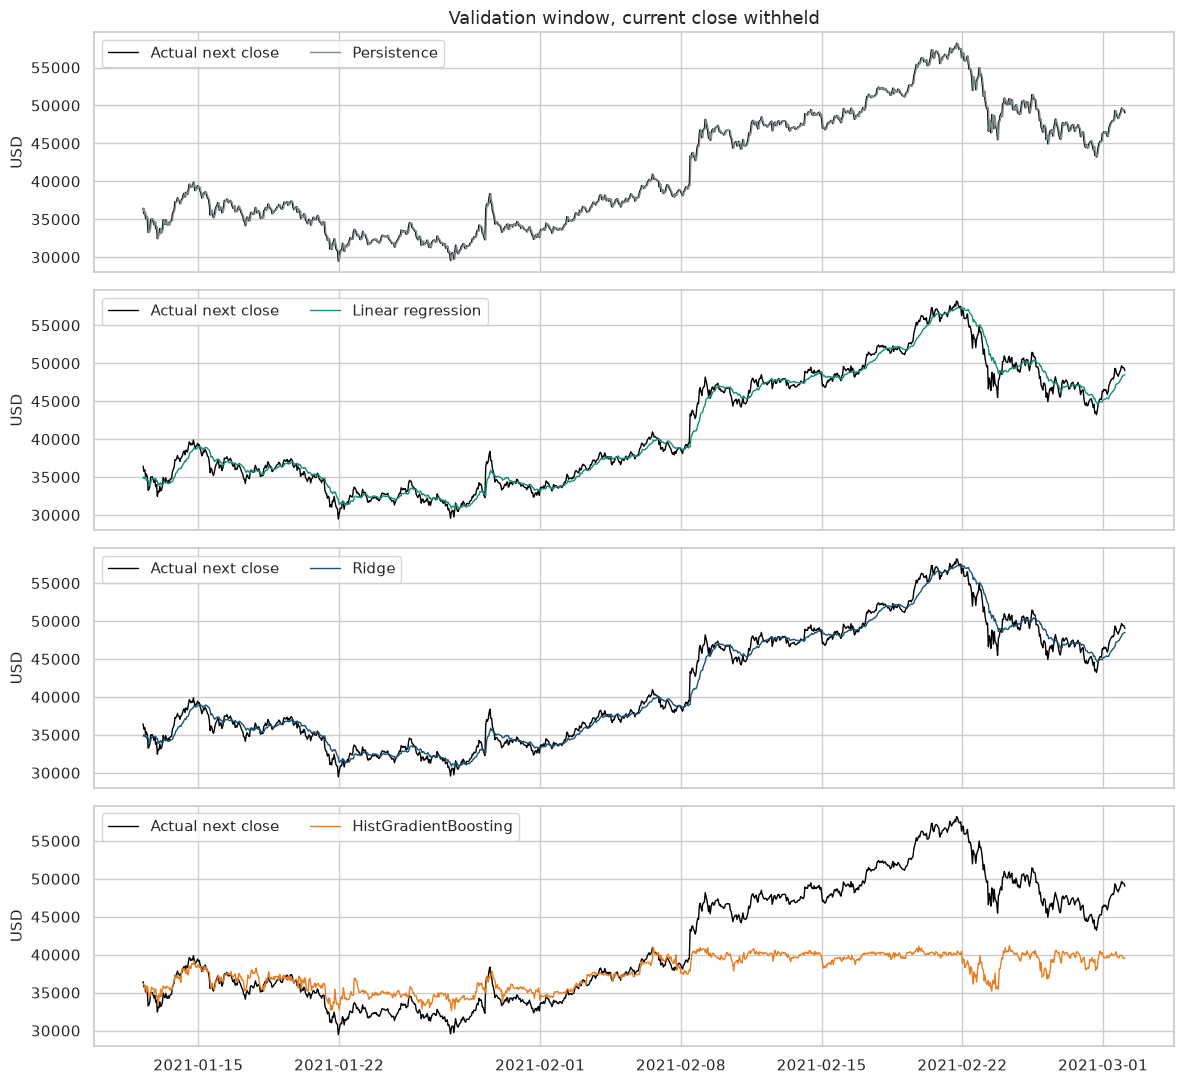

In [34]:
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
panel_colors = {
    "Persistence": "#7f8c8d",
    "Linear regression": "#148f77",
    "Ridge": "#1a5276",
    "HistGradientBoosting": "#e67e22",
}
for ax, name in zip(axes, panel_colors):
    ax.plot(valid.index, y_valid, color="black", linewidth=1.0, label="Actual next close")
    ax.plot(
        valid.index,
        validation_predictions[name],
        color=panel_colors[name],
        linewidth=1.0,
        label=name,
    )
    ax.set_ylabel("USD")
    ax.legend(loc="upper left", ncol=2)
axes[0].set_title("Validation window, current close withheld")
fig.tight_layout()
plt.show()


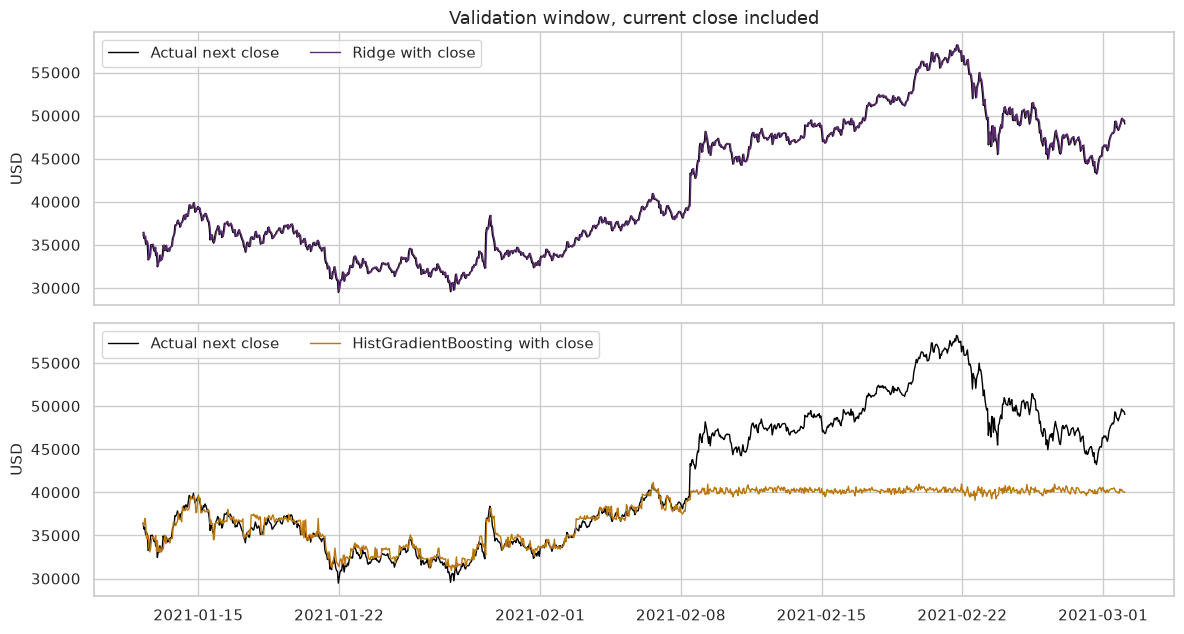

In [35]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
close_panels = {
    "Ridge with close": "#5b2c6f",
    "HistGradientBoosting with close": "#b9770e",
}
for ax, name in zip(axes, close_panels):
    ax.plot(valid.index, y_valid, color="black", linewidth=1.0, label="Actual next close")
    ax.plot(
        valid.index,
        validation_predictions[name],
        color=close_panels[name],
        linewidth=1.0,
        label=name,
    )
    ax.set_ylabel("USD")
    ax.legend(loc="upper left", ncol=2)
axes[0].set_title("Validation window, current close included")
fig.tight_layout()
plt.show()


### Test forecast

The test window was not used to choose hyperparameters or to pick the winner. Where the selected model is not persistence, its line is the refit forecast. The grey line is still the last observed close.

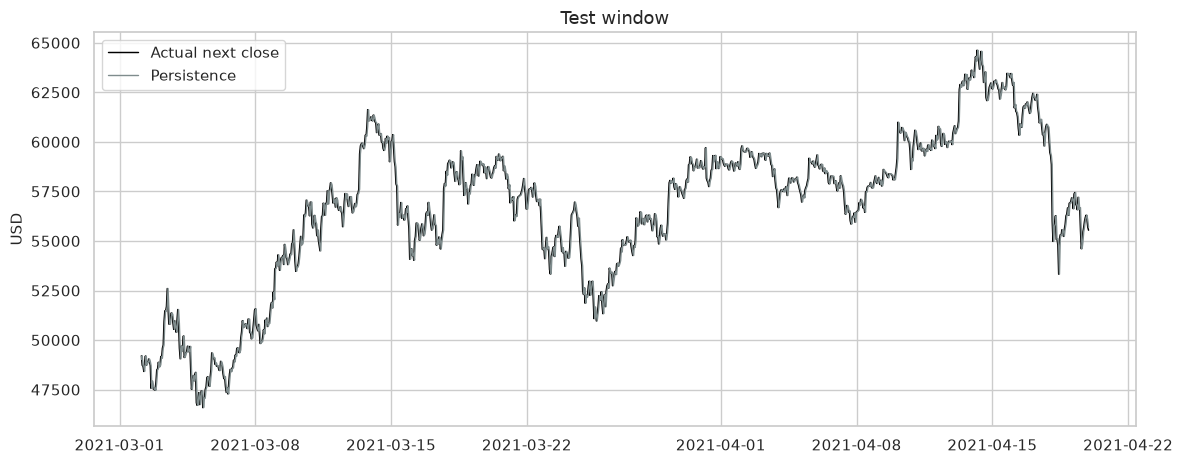

In [36]:
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(test.index, y_test, color="black", linewidth=1.05, label="Actual next close")
ax.plot(test.index, test["close"], color="#7f8c8d", linewidth=1.0, label="Persistence")
if winner != "Persistence":
    ax.plot(test.index, test_prediction, color="#e67e22", linewidth=1.0, label=f"{winner}, refit")
ax.set_ylabel("USD")
ax.set_title("Test window")
ax.legend(loc="best")
fig.tight_layout()
plt.show()

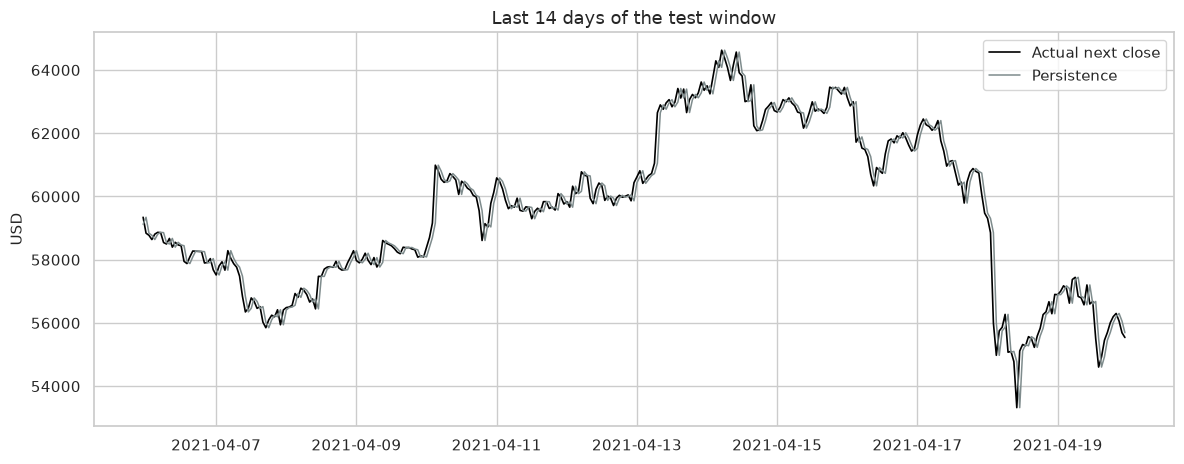

In [37]:
zoom_start = test.index.max() - pd.Timedelta(days=14)
zoom = test.index >= zoom_start

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(test.index[zoom], y_test.loc[zoom], color="black", linewidth=1.2, label="Actual next close")
ax.plot(test.index[zoom], test.loc[zoom, "close"], color="#7f8c8d", linewidth=1.1, label="Persistence")
if winner != "Persistence":
    ax.plot(
        test.index[zoom],
        np.asarray(test_prediction)[zoom],
        color="#e67e22",
        linewidth=1.1,
        label=f"{winner}, refit",
    )
ax.set_ylabel("USD")
ax.set_title("Last 14 days of the test window")
ax.legend(loc="best")
fig.tight_layout()
plt.show()

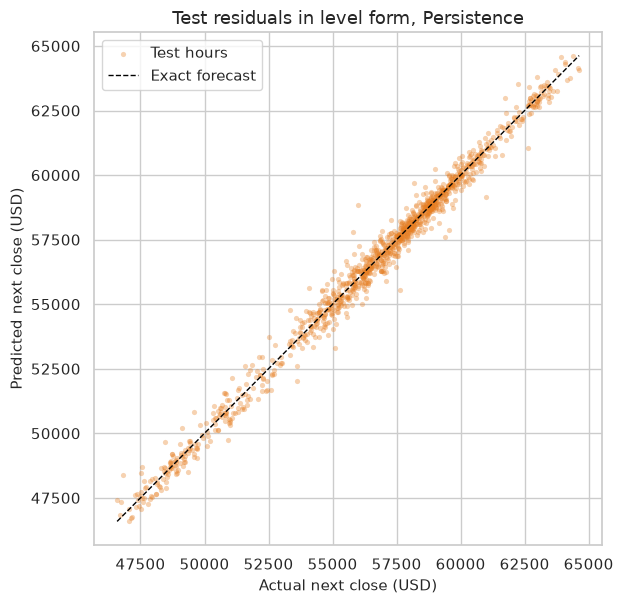

Mean residual (prediction minus actual): -5.56 USD
Residual standard deviation: 417.75 USD


In [38]:
actual = y_test.to_numpy()
predicted = np.asarray(test_prediction, dtype=float)
low = float(min(actual.min(), predicted.min()))
high = float(max(actual.max(), predicted.max()))

fig, ax = plt.subplots(figsize=(6.4, 6.2))
ax.scatter(actual, predicted, s=14, alpha=0.35, color="#e67e22", linewidths=0, label="Test hours")
ax.plot([low, high], [low, high], color="black", linestyle="--", linewidth=1, label="Exact forecast")
ax.set_xlabel("Actual next close (USD)")
ax.set_ylabel("Predicted next close (USD)")
ax.set_title(f"Test residuals in level form, {winner}")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

residual = predicted - actual
print(f"Mean residual (prediction minus actual): {residual.mean():.2f} USD")
print(f"Residual standard deviation: {residual.std():.2f} USD")

In the figure that withholds the current close, persistence lies on the actual line. Linear regression and ridge follow the same path a step behind, and the two lines match. Boosting follows into early February and then flattens near $40,000 while the actual close climbs toward $57,000. In the figure that includes the current close, ridge lies on the actual line and boosting still flattens near $40,000 after 8 February. The test chart is the persistence forecast only. Over the last 14 days of the test the price moves between about $54,000 and $64,000, and the grey line is one hour behind the black line. The scatter sits on the diagonal because the last close is already close to the next close, and the cloud around the line is the $418 residual scale.


### Q&A

The sample runs from 1 January 2020 to the early hours of 20 April 2021, at a one-minute grain with 3.8% of minutes missing. Bitcoin, Ether, and Litecoin all rise over that span, by 674%, 1,554%, and 523% on daily closes. All three bottom on 12 March 2020 and top in mid-April 2021.

Hourly returns move together: Bitcoin-Ether 0.82, Bitcoin-Litecoin 0.75. Both correlations are higher in the half of hours when Bitcoin's 24-hour volatility is above its median.

Lagged Bitcoin returns barely relate to the next hour. The correlations at 1, 6, and 24 hours are -0.059, -0.005, and -0.039. The 24-hour and 168-hour averages track the March 2020 crash from behind. The gap from the 24-hour average does not sort the next-hour return: the extreme deciles both average about 0.04%.

Volume and absolute returns vary by hour and by weekday. Hour 06:00 UTC is the quietest volume hour, at 0.559, 0.692, and 0.689 of each symbol's own average for Bitcoin, Ether, and Litecoin. Bitcoin is busiest at 14:00 UTC, at 1.608 times its average. Ether and Litecoin are busiest at 16:00 UTC, at 1.631 and 1.694. Thursday has the highest absolute return for all three. Saturday volume is 0.522 of Bitcoin's average and 0.655 of Ether's, and Saturday has the smallest absolute return for all three. Trailing 24-hour volume lines up with the size of the next move, from 0.28% mean absolute return in the quietest decile to 1.14% in the loudest.

The next-hour Bitcoin close is best predicted by the current close. Persistence validation MAE is $347.44. Without the current close, linear regression and ridge both have a validation MAE of $729.73, and gradient boosting has $4,995.70. With the current close, ridge's validation MAE is $347.65 and boosting's is $4,350.37. On the untouched test block the persistence MAE is $298.55 and the RMSE is $417.79.

### Data Analysis Key Findings

- Bitcoin's hourly return has mean 0.021% and standard deviation 0.89%, with single-hour extremes of -17.1% and +20.1%. The close fails a stationarity test (ADF p-value 0.99) and the return passes it (ADF statistic -19.2).
- The three markets share 18 outages of 23 hours each. Short-gap filling was not used, because no outage was shorter than that.
- Cross-market hourly correlations rise in volatile hours, from 0.77 to 0.84 for Bitcoin-Ether and from 0.67 to 0.78 for Bitcoin-Litecoin.
- Of 11,401 hourly timestamps, 7,818 are usable for the forecast after the 168-hour warm-up and the long outages. The test block is 2 March 2021 to 19 April 2021.
- Every fitted model has a training R-squared near 0.999. The lowest validation MAE is still persistence, at $347.44. Ridge that is allowed to see the current close is $0.21 worse. Boosting flattens once the price leaves the training range, with or without that close.

### Insights or Next Steps

- The hourly close behaves like a drifting random walk. A model of the next close has to be judged against the last close, in dollars, or a high R-squared will credit the trend.
- Giving ridge the current close ties persistence within $0.21 of validation MAE and does not beat it. The lags, moving averages, and the other two coins are not adding a next-hour price signal. Trailing volume does sort the size of the next move, so a volatility forecast is the natural next model.
